# Effectiveness of thrombolysis in early (4-hour) arrivals with mild stroke (NIHSS 1–5): doubly robust causal forest

**Good outcome = discharge mRS 0–2, or discharge mRS no worse than pre-stroke mRS**

## Summary

**Aim.** To estimate the effect of thrombolysis on good outcome at discharge in patients who received it, among patients with mild ischaemic stroke (NIHSS 1–5) arriving within 4 hours of onset. The effect is estimated by onset-to-thrombolysis window and by NIHSS, and its robustness is tested.

**Data.** SSNAP stroke admissions: 58,389 patients, of whom 13,380 (23%) were thrombolysed. Of these, 7,390 were treated within 180 minutes, 5,514 at 180–270 minutes and 476 at 270–360 minutes.

**Method.** A causal forest within a double machine learning framework (CausalForestDML, EconML), with LightGBM first-stage models and 5-fold cross-fitting. The main result is the doubly robust (AIPW) average treatment effect in the treated (ATT), with influence-function 95% CIs. Robustness is assessed with:
* model diagnostics (discrimination, calibration, overlap, best linear predictor test);
* comparison with the matched target trial emulation;
* 18 alternative specifications;
* E-values, sensemakr and leave-one-out analyses of the main confounders.

**Key results.**
* **Overall effect.** In thrombolysed patients, thrombolysis was associated with a **5.0 percentage-point** higher probability of a good outcome (95% CI 4.0 to 6.0), a risk ratio of 1.07 (1.05 to 1.08).
* **Timing.** The effect was largest with early treatment:
  * within 180 minutes: 6.3 points (5.1 to 7.6);
  * at 180–270 minutes: 3.5 (2.1 to 4.8);
  * at 270–360 minutes: 1.8 (−2.1 to 5.6), which is uncertain because only 476 patients were treated in this window.
* **Severity.** The effect depended strongly on NIHSS (test of homogeneity p < 0.001):
  * no detectable benefit at NIHSS 1 (−2.1, −4.8 to 0.7) or NIHSS 2 (0.2, −1.7 to 2.2);
  * clear benefit at NIHSS 3–5 (5.3, 5.9 and 7.1 points).
* **Agreement with the matched target trial emulation.** All estimates were within 2 points (overall 5.0 vs 5.7).
* **Robustness to analytic choices.** Across model settings, cohort definitions and random seeds, the overall estimate was 5.0 to 5.4 points. Two choices changed it:
  * adjusting for onset-to-scan time and year: 3.4 points (2.3 to 4.6);
  * the outcome definition: 2.4 points for mRS 0–3 to 6.6 points for mRS 0–1 or no worse.

  Benefit at NIHSS 3–5 and no benefit at NIHSS 1 held in every analysis.
* **Unmeasured confounding.**
  * Overall: E-value 1.34 (CI limit 1.29); sensemakr robustness value 4.6%.
  * NIHSS 3–5: more robust (robustness values 5.7–7.6%).
  * Leaving NIHSS out of the model removed the benefit (−0.9 points). Leaving out age or pre-stroke mRS changed it by less than 1 point.
* **Individual-level estimates.** The forest's individual effect estimates were only weakly calibrated (best linear predictor slopes 0.07–0.26). Variation in benefit is therefore described with subgroup ATTs rather than individual estimates.

**Conclusion.** Thrombolysis in mild stroke is associated with a modest benefit in the patients treated. It is concentrated in NIHSS 3–5 and early treatment, with no detectable benefit at NIHSS 1–2. The main threat to validity is unmeasured confounding, for example by non-disabling or rapidly improving symptoms.

## Selection criteria

* Arrival within 4 hours of known stroke onset time
* No thrombectomy
* Stroke type = infarction
* No recorded use of perfusion imaging
* Stroke severity (NIHSS) 1–5
* Thrombolysis, if given, within 360 minutes of onset
* Stroke team gave at least 10 thrombolyses in the cohort

## Outcome

* Good outcome: discharge mRS 0–2, **or** discharge mRS no worse than pre-stroke mRS

## Treatment

* Onset-to-thrombolysis time, grouped as < 180, 180–270 and 270–360 minutes, compared with no thrombolysis

## Adjustment features

* Pre-stroke disability (mRS), stroke severity (NIHSS), age
* Congestive heart failure, hypertension, diabetes
* Atrial fibrillation anticoagulant, any atrial fibrillation diagnosis
* Ethnicity, stroke team

## Method overview

To estimate how the effect of thrombolysis varied between patients, we used a causal forest estimated within a double machine learning framework (CausalForestDML, EconML). In clinical terms, the method asks: for patients who look alike, did those who received thrombolysis do better than we would have expected them to? It works in two stages.

In the first stage, two prediction models were built with gradient-boosted decision trees (LightGBM). The first predicted each patient's probability of a good outcome (mRS 0–2 or no worse than pre-stroke) from their baseline characteristics and stroke team, without knowing the treatment given. These characteristics were age, stroke severity, pre-stroke disability, comorbidities, atrial fibrillation and anticoagulation status, and ethnicity. The second predicted the probability of each treatment category from the same information: no thrombolysis, or thrombolysis within <180, 180–270 or 270–360 minutes of onset. It therefore captures the clinical and organisational factors that influence who is treated.

The models used five-fold cross-fitting, so each patient's predictions came from models trained on other patients. Subtracting the predictions from what actually happened left two residuals: how much better or worse each patient's outcome was than expected, and how far their treatment differed from what would typically be given to someone like them. Removing the predictable part of both treatment and outcome adjusts for measured confounding, including confounding by indication. A further advantage is that small errors in either prediction model have only a limited, second-order effect on the final estimates.

In the second stage, a forest of 2,000 "honest" trees related the outcome residuals to the treatment residuals. Each tree used one half of its data to choose how to split patients into subgroups and the other half to estimate the treatment effect within them, which reduces overfitting. The result was an estimated absolute change in the probability of a good outcome for each patient under each treatment window compared with no thrombolysis. These estimates were then summarised by treatment window and by patient characteristics.

As with any observational analysis, the estimates assume there is no important unmeasured confounding, and that comparable patients were found in both the treated and untreated groups.

![](./images/dml_causal_forest_thrombolysis_method.png)

## What this notebook estimates

For each onset-to-thrombolysis window, and for all thrombolysed patients combined, compared with no thrombolysis:

| Estimate | Meaning | How it is calculated |
|---|---|---|
| **ATT** (main result) | Average effect in the patients who were actually thrombolysed in that window | Doubly robust (augmented inverse-probability-weighted, AIPW) estimate from the cross-fitted first-stage models and the forest, with 95% CI |
| **ATT by NIHSS** | The same, within each NIHSS score | AIPW within each NIHSS score, so directly comparable with the matched target trial emulation by NIHSS |
| **Risk ratio in the treated** | Relative effect in the treated | Observed proportion with a good outcome divided by the doubly robust estimate of that proportion without thrombolysis |
| **ATE** | Average effect if *everyone* in the cohort were thrombolysed in that window | AIPW over all patients; only reported where positivity holds for most of the cohort |
| **Mean CATE in treated** | Simple average of the forest's individual-level estimates | Plug-in average (no CI) |

Effects are differences in the probability of a good outcome, in percentage points.

Confidence intervals come from the influence function of the AIPW estimator. They are not based on the spread of individual CATEs, which measures variation between patients rather than uncertainty in the average. Differences between subgroups are tested with a chi-square test of homogeneity of subgroup ATTs.

## Notebook structure

1. **Set-up**: modules, settings and features
2. **Cohort selection and treatment groups**
3. **Descriptive statistics**
4. **Model**: definition and fitting
5. **Model diagnostics**: first-stage performance and overlap
6. **Treatment effects**: ATT, ATE and mean CATE
7. **Effects by NIHSS score**, and comparison with the matched target trial emulation
8. **Effects in subgroups** of patients treated within 270 minutes
9. **Relative effects, first-stage performance and a test of heterogeneity**
10. **Sensitivity analyses**: alternative specifications, E-values, sensemakr, leave-one-out
11. **Summary of observations and conclusions**

# 1. Set-up

## 1.1 Load modules

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from econml.dml import CausalForestDML  # causal forest within double machine learning
from lightgbm import LGBMClassifier
from scipy import stats
from sklearn.metrics import roc_auc_score

warnings.filterwarnings("ignore")

## 1.2 Settings

All analysis choices are set here; the sensitivity analyses change one at a time.

* **Good outcome:** discharge mRS ≤ 2 (`MRS_TARGET`), or no worse than pre-stroke mRS.
* **Cohort:** NIHSS 1–5, arrival within 240 minutes (`MAX_ARRIVAL`), thrombolysis within 360 minutes (`MAX_THROMBOLYSIS`), and teams that gave at least 10 thrombolyses (`MIN_TEAM_THROMBOLYSIS`). 99,999 minutes (`NO_TREATMENT`) means "not thrombolysed".
* **First-stage models:** LightGBM with 400 trees, 31 leaves, learning rate 0.03 and 80% row and column subsampling (`NUISANCE_PARAMS`), with 5 cross-fitting folds (`CV_FOLDS`).
* **Causal forest:** 2,000 honest trees (`N_TREES`) with at least 25 patients per leaf (`MIN_SAMPLES_LEAF`).
* **AIPW:**
  * Treatment probabilities are clipped at 0.01 (`PROPENSITY_CLIP`).
  * The ATE is reported only if fewer than 20% of patients have a probability of the window below 0.01 (`ATE_MAX_CLIPPED_PCT`).
  * Subgroup ATTs need at least 30 treated patients (`MIN_SUBGROUP_TREATED`).
* **Comparison:** the summary file of the matched target trial emulation (`TTE_SUMMARY_PATH`).

In [2]:
prefix = "mild_stroke_early_arrival_good_outcome_causal_forest"
DATA_PATH = "../data/sam3/cleaned_data_anon_teams.csv"
OUTPUT_DIR = "./output"
TTE_SUMMARY_PATH = ("../4_target_trial_emulation/output/"
                    "mild_stroke_by_nihss_1_to_5_early_arrival_good_outcome_target_trial_summary_full.csv")

MRS_TARGET = 2                 # good outcome: discharge mRS <= MRS_TARGET, or no worse than pre-stroke mRS

# Cohort
NIHSS_VALUES = [1, 2, 3, 4, 5]
MAX_ARRIVAL = 240              # include patients arriving within this many minutes of onset
MAX_THROMBOLYSIS = 360         # exclude thrombolysis later than this
MIN_TEAM_THROMBOLYSIS = 10     # include teams that gave at least this many thrombolyses in the cohort
NO_TREATMENT = 99999           # sentinel time meaning "not thrombolysed"
TIME_THROMBOLYSIS = "onset_to_thrombolysis_time"

# First-stage (nuisance) models: LightGBM gradient-boosted trees
SEED = 42
NUISANCE_PARAMS = dict(n_estimators=400, num_leaves=31, learning_rate=0.03,
                       subsample=0.8, colsample_bytree=0.8, n_jobs=-1, verbosity=-1)
CV_FOLDS = 5                   # cross-fitting folds

# Second stage: causal forest
N_TREES = 2000
MIN_SAMPLES_LEAF = 25

# Doubly robust (AIPW) estimates
PROPENSITY_CLIP = 0.01         # lower limit for treatment probabilities
ATE_MAX_CLIPPED_PCT = 20       # report ATE only if fewer than this % of patients have P(window) < PROPENSITY_CLIP
MIN_SUBGROUP_TREATED = 30      # minimum treated patients to report a subgroup ATT

## 1.3 Define features

* **X (effect modifiers):** pre-treatment clinical features that the effect of thrombolysis may vary with. The forest splits on these.
* **W (confounders):** features adjusted for in the first-stage models. These are X plus stroke team, which captures differences in practice between hospitals.
* **Categorical features** (stroke team, ethnicity) are coded as integers and handled natively by LightGBM.
* **Treatment groups:** no thrombolysis (the control), and thrombolysis at < 180, 180–270 or 270–360 minutes. Codes are prefixed with a number so that EconML uses no thrombolysis as the baseline.

The primary model does not adjust for onset-to-scan time or year. Adding them is a sensitivity analysis (Section 10).

In [3]:
X_FEATURES = [
    'prior_disability',
    'stroke_severity',
    'age',
    'congestive_heart_failure',
    'hypertension',
    'diabetes',
    'afib_anticoagulant',
    'any_afib_diagnosis',
    'ethnicity',
]
W_FEATURES = X_FEATURES + ['stroke_team']
CATEGORICAL_FEATURES = ['stroke_team', 'ethnicity']

# Treatment groups. EconML one-hot encodes a discrete treatment and uses the first level
# (alphabetically) as the baseline, so codes are prefixed with a number to fix the order.
CONTROL_GROUP = "No thrombolysis"
GROUP_ORDER = ["<180 min", "180-270 min", "270-360 min"]
ALL_TREATED = "All (≤360 min)"
ARM_CODES = {
    "No thrombolysis": "0_No_thrombolysis",
    "<180 min": "1_<180_min",
    "180-270 min": "2_180-270_min",
    "270-360 min": "3_270-360_min",
}
BASELINE_ARM = ARM_CODES[CONTROL_GROUP]
CODE_TO_GROUP = {code: group for group, code in ARM_CODES.items()}

# Treatment definitions for which effects are reported: each window, and all windows combined
TREATMENT_SETS = {ALL_TREATED: GROUP_ORDER, **{g: [g] for g in GROUP_ORDER}}
NIHSS_LABELS = ["1-5"] + [str(n) for n in NIHSS_VALUES]

# 2. Cohort selection and treatment groups

The cohort is the same as in the matched target trial emulation (`4_target_trial_emulation/02_...`). Patients are included if they:

* had an ischaemic stroke and a recorded discharge mRS
* arrived within 4 hours of onset
* had no perfusion imaging and no thrombectomy
* had NIHSS 1–5
* were seen by a team that gave at least 10 thrombolyses in the cohort

Thrombolysis more than 360 minutes after onset is excluded. Thrombolysed patients are grouped as < 180 min (≤ 180), 180–270 min and 270–360 min. The table shows the number of patients remaining after each step.

In [4]:
def good_outcome(df, mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # 1 if discharge mRS <= mrs_target, or (optionally) discharge mRS no worse than pre-stroke mRS
    outcome = df["discharge_disability"] <= mrs_target
    if allow_no_worse_than_prior:
        outcome = outcome | (df["discharge_disability"] <= df["prior_disability"])
    return outcome.astype(int)


def assign_time_groups(df):
    # Onset-to-thrombolysis window; untreated patients (sentinel time) are the control group
    time_ = df[TIME_THROMBOLYSIS]
    group = pd.Series(CONTROL_GROUP, index=df.index, dtype=object)
    group[time_ <= 180] = "<180 min"
    group[(time_ > 180) & (time_ <= 270)] = "180-270 min"
    group[(time_ > 270) & (time_ <= 360)] = "270-360 min"
    df["treatment_group"] = group
    return df


def build_cohort(raw, max_arrival=MAX_ARRIVAL, min_team_thrombolysis=MIN_TEAM_THROMBOLYSIS,
                 extra_features=(), verbose=False):
    # Apply eligibility criteria and add outcome, treatment group and patient id.
    # extra_features: additional W columns (missing values coded as -1).
    df = raw.copy()
    # Onset-to-scan time = onset-to-arrival + arrival-to-scan (used only in a sensitivity analysis)
    df["onset_to_scan_time"] = df["onset_to_arrival_time"] + df["arrival_to_scan_time"]
    log = [("All records", len(df))]

    def keep_rows(label, mask):
        nonlocal df
        df = df[mask]
        log.append((label, len(df)))

    keep_rows("Discharge mRS recorded", df["discharge_disability"].notna())
    keep_rows("Infarction", df["infarction"] == 1)
    keep_rows(f"Arrival within {max_arrival} min of onset", df["onset_to_arrival_time"] < max_arrival)
    keep_rows("No perfusion imaging", df["perfusion_imaging_used"] == 0)
    keep_rows("No thrombectomy", df["thrombectomy"] == 0)
    keep_rows("NIHSS 1-5", df["stroke_severity"].between(1, 5))
    team_counts = df.groupby("stroke_team")[TIME_THROMBOLYSIS].count()
    keep_rows(f"Team gave >= {min_team_thrombolysis} thrombolyses",
              df["stroke_team"].isin(team_counts.index[team_counts >= min_team_thrombolysis]))

    df = df.copy()
    df[TIME_THROMBOLYSIS] = df[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)
    keep_rows(f"Thrombolysis (if given) <= {MAX_THROMBOLYSIS} min",
              (df[TIME_THROMBOLYSIS] <= MAX_THROMBOLYSIS) | (df[TIME_THROMBOLYSIS] == NO_TREATMENT))

    df = df.copy()
    for feature in extra_features:
        df[feature] = df[feature].fillna(-1)
    df["outcome_target"] = good_outcome(df)
    df = assign_time_groups(df)
    df["patient_id"] = np.arange(len(df))
    if verbose:
        display(pd.DataFrame(log, columns=["Step", "Patients remaining"]))
    return df


raw_data = pd.read_csv(DATA_PATH, low_memory=False)
data = build_cohort(raw_data, verbose=True)
data["treatment_group"].value_counts().reindex([CONTROL_GROUP] + GROUP_ORDER).rename("patients").to_frame()

,Step,Patients remaining
0,All records,452863
1,Discharge mRS recorded,438589
2,Infarction,384365
3,Arrival within 240 min of onset,135944
4,No perfusion imaging,133895
5,No thrombectomy,125703
6,NIHSS 1-5,58514
7,Team gave >= 10 thrombolyses,58458
8,Thrombolysis (if given) <= 360 min,58389


,patients
treatment_group,
No thrombolysis,45009
<180 min,7390
180-270 min,5514
270-360 min,476


**Results.** 58,389 patients are included, of whom 13,380 (23%) were thrombolysed:

* 7,390 within 180 minutes
* 5,514 at 180–270 minutes
* 476 at 270–360 minutes

45,009 patients were not thrombolysed.

## 2.1 Patient flow diagram

The flow diagram gives the number of patients at each selection step, from the cleaned SSNAP data to the analysed cohort and the treatment groups. The steps are replayed on the raw data in the same order and with the same rules as the cohort selection above, and the final count is checked against the analysed cohort.

The first cell defines the diagram. The second draws it and saves the diagram (PNG) and the counts (CSV) to `output/`.

In [5]:
# Patient flow diagram: functions
FLOW_GROUP_LABELS = {
    CONTROL_GROUP: "No\nthrombolysis",
    "<180 min": "Thrombolysis\n< 180 min",
    "180-270 min": "Thrombolysis\n180–270 min",
    "270-360 min": "Thrombolysis\n270–360 min",
}


def cohort_flow_steps(raw, max_arrival=MAX_ARRIVAL, min_team_thrombolysis=MIN_TEAM_THROMBOLYSIS):
    """Replay the cohort selection on the raw data, returning (n remaining, exclusion label, n excluded)
    for each step, in the same order and with the same rules as build_cohort."""
    df = raw.copy()
    steps = [(len(df), None, 0)]

    def keep(label, mask):
        nonlocal df
        n_before = len(df)
        df = df[mask]
        steps.append((len(df), label, n_before - len(df)))

    keep("no discharge mRS recorded", df["discharge_disability"].notna())
    keep("not ischaemic stroke", df["infarction"] == 1)
    keep(f"arrived {max_arrival // 60} hours or more after onset, or onset time unknown",
         df["onset_to_arrival_time"] < max_arrival)
    keep("perfusion imaging used", df["perfusion_imaging_used"] == 0)
    keep("thrombectomy given", df["thrombectomy"] == 0)
    keep("NIHSS 0, above 5 or missing", df["stroke_severity"].between(1, 5))
    team_counts = df.groupby("stroke_team")[TIME_THROMBOLYSIS].count()
    keep(f"stroke team gave fewer than {min_team_thrombolysis} thrombolyses in this cohort",
         df["stroke_team"].isin(team_counts.index[team_counts >= min_team_thrombolysis]))
    lysis = df[TIME_THROMBOLYSIS].fillna(NO_TREATMENT)
    keep(f"thrombolysis more than {MAX_THROMBOLYSIS // 60} hours after onset",
         (lysis <= MAX_THROMBOLYSIS) | (lysis == NO_TREATMENT))
    return steps


def plot_flow_diagram(steps, cohort_label, groups, filename, extra_steps=(), footnote=""):
    """CONSORT-style patient flow diagram.

    steps: output of cohort_flow_steps; extra_steps: further (n remaining, exclusion label, n excluded)
    steps after the cohort (e.g. missing data); groups: list of (group code, list of text lines)."""
    all_steps = list(steps) + list(extra_steps)
    n_excl = len(all_steps) - 1
    step_h = 0.55
    width = 12.0
    height = 2.2 + step_h * n_excl + 2.4
    fig, ax = plt.subplots(figsize=(width * 0.85, height * 0.85))
    ax.set_xlim(0, width)
    ax.set_ylim(0, height)
    ax.axis("off")
    main_box = dict(boxstyle="round,pad=0.4", fc="white", ec="#333333", lw=0.9)
    excl_box = dict(boxstyle="round,pad=0.3", fc="#f3f3f3", ec="#888888", lw=0.6)
    arrow = dict(arrowstyle="-|>", lw=0.9, color="#333333")
    x_main = 3.4

    y = height - 0.6
    ax.text(x_main, y, f"Admissions in cleaned SSNAP data, 2020-2025\nn = {all_steps[0][0]:,}",
            ha="center", va="center", fontsize=9, bbox=main_box)
    y_top = y - 0.35
    y_ex = y_top - 0.45
    for n_remaining, label, n_excluded in all_steps[1:]:
        ax.plot([x_main, 6.2], [y_ex, y_ex], color="#888888", lw=0.7)
        ax.text(6.25, y_ex, f"Excluded: {label} (n = {n_excluded:,})", ha="left", va="center",
                fontsize=8, bbox=excl_box)
        y_ex -= step_h
    y_cohort = y_ex - 0.15
    ax.annotate("", xy=(x_main, y_cohort + 0.35), xytext=(x_main, y_top), arrowprops=arrow)
    ax.text(x_main, y_cohort, f"{cohort_label}\nn = {all_steps[-1][0]:,}", ha="center", va="center",
            fontsize=9, fontweight="bold", bbox=main_box)

    # Branch to treatment groups
    n_groups = len(groups)
    xs = [width * (i + 0.5) / n_groups for i in range(n_groups)]
    y_bar = y_cohort - 0.75
    y_groups = y_bar - 0.9
    ax.plot([x_main, x_main], [y_cohort - 0.35, y_bar], color="#333333", lw=0.9)
    ax.plot([xs[0], xs[-1]], [y_bar, y_bar], color="#333333", lw=0.9)
    for x, (code, lines) in zip(xs, groups):
        ax.annotate("", xy=(x, y_groups + 0.55), xytext=(x, y_bar), arrowprops=arrow)
        text = FLOW_GROUP_LABELS.get(code, code) + "\n" + "\n".join(lines)
        ax.text(x, y_groups, text, ha="center", va="top" if False else "center", fontsize=7.5,
                bbox=dict(main_box, fc="#eef4fb" if code != CONTROL_GROUP else "#fdf1ea"))
    if footnote:
        ax.text(0.1, 0.15, footnote, ha="left", va="bottom", fontsize=7, color="#555555")
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

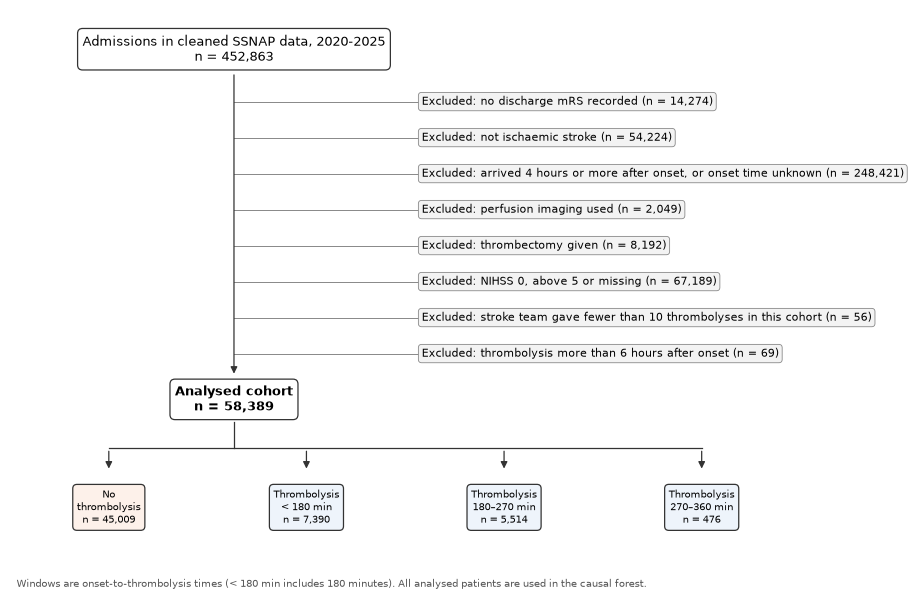

,n_remaining,excluded_reason,n_excluded
0,452863,NaN,0
1,438589,no discharge mRS recorded,14274
2,384365,not ischaemic stroke,54224
3,135944,"arrived 4 hours or more after onset, or onset ...",248421
4,133895,perfusion imaging used,2049
5,125703,thrombectomy given,8192
6,58514,"NIHSS 0, above 5 or missing",67189
7,58458,stroke team gave fewer than 10 thrombolyses in...,56
8,58389,thrombolysis more than 6 hours after onset,69


In [6]:
# Patient flow diagram: cohort selection and treatment groups
flow_steps = cohort_flow_steps(raw_data)
# Check: the replayed selection gives the same cohort as build_cohort
assert flow_steps[-1][0] == len(data), "Flow counts do not match the cohort in data"

group_counts = data["treatment_group"].value_counts()
flow_groups = [(group, [f"n = {group_counts[group]:,}"]) for group in [CONTROL_GROUP] + GROUP_ORDER]

plot_flow_diagram(
    flow_steps, "Analysed cohort", flow_groups, f"{OUTPUT_DIR}/{prefix}_flow_diagram.png",
    footnote="Windows are onset-to-thrombolysis times (< 180 min includes 180 minutes). "
             "All analysed patients are used in the causal forest.")
flow_counts = pd.DataFrame(flow_steps, columns=["n_remaining", "excluded_reason", "n_excluded"])
flow_counts.to_csv(f"{OUTPUT_DIR}/{prefix}_flow_counts.csv", index=False)
flow_counts

**Results.** The replayed selection gives the same 58,389 patients as the cohort selection. Exclusions, in order:

| Step | Excluded |
|---|---|
| No discharge mRS recorded | 14,274 |
| Not ischaemic stroke | 54,224 |
| Arrived 4 hours or more after onset, or onset time unknown | 248,421 |
| Perfusion imaging used | 2,049 |
| Thrombectomy given | 8,192 |
| NIHSS 0, above 5 or missing | 67,189 |
| Stroke team gave fewer than 10 thrombolyses | 56 |
| Thrombolysis more than 6 hours after onset | 69 |

Most exclusions are for late or unknown arrival and for stroke severity outside the mild range.

# 3. Descriptive statistics

Baseline characteristics by treatment group, shown as mean ± SD, followed by the mean (SD) onset-to-thrombolysis time in each window. The differences between groups are the confounding that the first-stage models have to remove.

In [7]:
descriptive_features = [f for f in X_FEATURES if f != "ethnicity"]
stats_by_group = data.groupby("treatment_group")[descriptive_features].agg(["mean", "std", "count"])
formatted_descriptive_stats = pd.DataFrame({
    group: [f"{stats_by_group.loc[group, (f, 'mean')]:.2f} ± {stats_by_group.loc[group, (f, 'std')]:.2f} "
            f"(n={int(stats_by_group.loc[group, (f, 'count')])})" for f in descriptive_features]
    for group in [CONTROL_GROUP] + GROUP_ORDER
}, index=[f.replace("_", " ") for f in descriptive_features])
display(formatted_descriptive_stats)

# Onset-to-thrombolysis time by window (treated patients)
(data[data["treatment_group"] != CONTROL_GROUP]
 .groupby("treatment_group")[TIME_THROMBOLYSIS].agg(["mean", "std", "count"])
 .reindex(GROUP_ORDER).round(1))

,No thrombolysis,<180 min,180-270 min,270-360 min
prior disability,0.97 ± 1.25 (n=45009),0.49 ± 0.91 (n=7390),0.57 ± 0.97 (n=5514),0.47 ± 0.84 (n=476)
stroke severity,2.66 ± 1.30 (n=45009),3.72 ± 1.17 (n=7390),3.64 ± 1.21 (n=5514),3.46 ± 1.26 (n=476)
age,73.91 ± 13.21 (n=45009),70.45 ± 12.92 (n=7390),70.55 ± 13.27 (n=5514),69.30 ± 13.56 (n=476)
congestive heart failure,0.06 ± 0.23 (n=45009),0.04 ± 0.18 (n=7390),0.04 ± 0.19 (n=5514),0.02 ± 0.14 (n=476)
hypertension,0.57 ± 0.50 (n=45009),0.50 ± 0.50 (n=7390),0.53 ± 0.50 (n=5514),0.51 ± 0.50 (n=476)
diabetes,0.23 ± 0.42 (n=45009),0.18 ± 0.38 (n=7390),0.20 ± 0.40 (n=5514),0.19 ± 0.39 (n=476)
afib anticoagulant,0.19 ± 0.39 (n=45009),0.02 ± 0.14 (n=7390),0.02 ± 0.15 (n=5514),0.03 ± 0.18 (n=476)
any afib diagnosis,0.25 ± 0.43 (n=45009),0.12 ± 0.33 (n=7390),0.12 ± 0.33 (n=5514),0.13 ± 0.33 (n=476)


,mean,std,count
treatment_group,,,
<180 min,136.7,28.8,7390
180-270 min,221.7,25.7,5514
270-360 min,294.0,22.2,476


**Results.** Compared with untreated patients, thrombolysed patients:

* have more severe strokes within the mild range (mean NIHSS 3.5–3.7 vs 2.7);
* have less pre-stroke disability (mean mRS 0.5–0.6 vs 1.0);
* are younger (mean age 69–71 vs 74 years);
* are much less likely to be on anticoagulants (2–3% vs 19%), because anticoagulation is a contraindication to thrombolysis;
* are less likely to have atrial fibrillation (12–13% vs 25%).

The three treatment windows are similar to each other. Mean onset-to-thrombolysis time is 137 minutes (SD 29) for < 180 min, 222 (26) for 180–270 min and 294 (22) for 270–360 min.

## 3.1 Observed outcomes by treatment group

The table gives, for each treatment group and for all thrombolysed patients combined:
* the unadjusted number and percentage with a good outcome;
* in-hospital deaths;
* length of stay (median and IQR).

These are printed as LaTeX rows for the paper's supplementary table (TARGET items 10 and 12). Counts below 10 are suppressed. The comparisons are unadjusted, so differences between groups include confounding.

In [8]:
# Observed (unadjusted) good outcome, in-hospital death and length of stay by treatment group,
# shown as a table and printed as LaTeX rows for the paper's supplementary table (TARGET items 10 and 12).
# Counts below 10 are suppressed, as elsewhere in the paper.
OBSERVED_LABELS = {
    CONTROL_GROUP: "No thrombolysis",
    "<180 min": "Thrombolysis < 180 min",
    "180-270 min": "Thrombolysis 180--270 min",
    "270-360 min": "Thrombolysis 270--360 min",
    ALL_TREATED: "All thrombolysed ($\\leq$ 360 min)",
}


def count_pct(k, n, latex=False):
    """'k (p%)', or '<10' if the count is below 10."""
    k, n = int(k), int(n)
    if k < 10:
        return "$<$10" if latex else "<10"
    percent = "\\%" if latex else "%"
    return f"{k:,} ({100 * k / n:.1f}{percent})"


observed = pd.DataFrame({
    "group": data["treatment_group"].astype(str),
    "good": good_outcome(data),
    "death": pd.to_numeric(data["death"], errors="coerce"),
    "los": pd.to_numeric(data["length_of_stay"], errors="coerce"),
})
groups_to_report = [CONTROL_GROUP] + GROUP_ORDER + [ALL_TREATED]
observed_rows = []
for group in groups_to_report:
    rows = observed[observed["group"] != CONTROL_GROUP] if group == ALL_TREATED else observed[observed["group"] == group]
    n = len(rows)
    q1, med, q3 = rows["los"].quantile([0.25, 0.5, 0.75])
    observed_rows.append({"group": group, "n": n, "good_k": int(rows["good"].sum()),
                          "death_k": int((rows["death"] == 1).sum()), "los_median": med, "los_q1": q1, "los_q3": q3})
observed_outcomes = pd.DataFrame(observed_rows).set_index("group")
observed_outcomes.to_csv(f"{OUTPUT_DIR}/{prefix}_observed_outcomes.csv")

print(f"{len(observed):,} patients; missing death: {observed['death'].isna().sum()}, "
      f"missing length of stay: {observed['los'].isna().sum()}")
display(pd.DataFrame({
    "n": observed_outcomes["n"],
    "Good outcome, n (%)": [count_pct(r.good_k, r.n) for r in observed_outcomes.itertuples()],
    "In-hospital death, n (%)": [count_pct(r.death_k, r.n) for r in observed_outcomes.itertuples()],
    "Length of stay, days, median (IQR)": [f"{r.los_median:.0f} ({r.los_q1:.0f} to {r.los_q3:.0f})"
                                           for r in observed_outcomes.itertuples()],
}))

print("% ---- Observed outcomes: group & n & good outcome & in-hospital death & length of stay ----")
for group, r in observed_outcomes.iterrows():
    print(f"{OBSERVED_LABELS.get(group, group)} & {int(r['n']):,} & {count_pct(r['good_k'], r['n'], True)} & "
          f"{count_pct(r['death_k'], r['n'], True)} & {r['los_median']:.0f} ({r['los_q1']:.0f}--{r['los_q3']:.0f}) \\\\")

58,389 patients; missing death: 0, missing length of stay: 2


,n,"Good outcome, n (%)","In-hospital death, n (%)","Length of stay, days, median (IQR)"
group,,,,
No thrombolysis,45009,"33,216 (73.8%)",965 (2.1%),4 (2 to 11)
<180 min,7390,"5,818 (78.7%)",130 (1.8%),3 (2 to 7)
180-270 min,5514,"4,177 (75.8%)",129 (2.3%),3 (2 to 9)
270-360 min,476,367 (77.1%),14 (2.9%),3 (2 to 9)
All (≤360 min),13380,"10,362 (77.4%)",273 (2.0%),3 (2 to 8)


% ---- Observed outcomes: group & n & good outcome & in-hospital death & length of stay ----
No thrombolysis & 45,009 & 33,216 (73.8\%) & 965 (2.1\%) & 4 (2--11) \\
Thrombolysis < 180 min & 7,390 & 5,818 (78.7\%) & 130 (1.8\%) & 3 (2--7) \\
Thrombolysis 180--270 min & 5,514 & 4,177 (75.8\%) & 129 (2.3\%) & 3 (2--9) \\
Thrombolysis 270--360 min & 476 & 367 (77.1\%) & 14 (2.9\%) & 3 (2--9) \\
All thrombolysed ($\leq$ 360 min) & 13,380 & 10,362 (77.4\%) & 273 (2.0\%) & 3 (2--8) \\


**Results.**

| Group | n | Good outcome | In-hospital death | Length of stay, days (median, IQR) |
|---|---|---|---|---|
| No thrombolysis | 45,009 | 73.8% | 2.1% | 4 (2 to 11) |
| < 180 min | 7,390 | 78.7% | 1.8% | 3 (2 to 7) |
| 180–270 min | 5,514 | 75.8% | 2.3% | 3 (2 to 9) |
| 270–360 min | 476 | 77.1% | 2.9% | 3 (2 to 9) |
| All thrombolysed | 13,380 | 77.4% | 2.0% | 3 (2 to 8) |

* A good outcome was 3.6 points more common in thrombolysed than untreated patients (77.4% vs 73.8%).
* In-hospital death was rare (about 2%) and similar in all groups.
* Thrombolysed patients had a slightly shorter median length of stay (3 vs 4 days). Length of stay is missing for 2 patients.

Thrombolysed patients had more severe strokes but were younger and less disabled before the stroke (Section 3). The adjusted estimates in Sections 6–7 account for these differences.

# 4. Model

### First-stage (nuisance) models

Two LightGBM models are fitted with 5-fold cross-fitting, so each patient's predictions come from models trained on other patients:

* **outcome model:** probability of a good outcome given `[X, W]`
* **treatment model:** probability of each treatment group given `[X, W]` (the propensity scores)

LightGBM ignores `categorical_feature` when it is passed to the constructor, so a small wrapper class passes it to `.fit()`. EconML fits both models on `hstack([X, W])`, so categorical column indices refer to that combined matrix.

### Second stage: causal forest

A forest of 2,000 honest trees, each with at least 25 patients per leaf, relates outcome residuals to treatment residuals as a function of X. "Honest" means each tree uses half its sample to choose splits and the other half to estimate effects.

### Doubly robust (AIPW) estimates

The DML model implies a predicted outcome without thrombolysis for each patient, μ₀ = m − Σⱼ θⱼ pⱼ. Here m is the predicted outcome, θⱼ the forest's effect of window j, and pⱼ the probability of window j.

The **ATT** for a set of windows (one window, or all combined) is calculated as follows:

* each treated patient's outcome minus their μ₀
* minus untreated patients' outcome minus their μ₀, reweighted by the odds P(treated) / P(untreated)
* divided by the number treated

It is consistent if either the outcome or the treatment model is correct. The 95% CI comes from the influence function. Applying the same calculation within a subgroup (for example one NIHSS score) gives a subgroup ATT with a valid CI. Propensities are clipped at `PROPENSITY_CLIP` (0.01).

In [9]:
class CatLGBMClassifier(LGBMClassifier):
    # LightGBM classifier that passes categorical column indices to .fit()
    def __init__(self, cat_features="auto", **kwargs):
        self.cat_features = cat_features
        super().__init__(**kwargs)

    def get_params(self, deep=True):
        params = super().get_params(deep=deep)
        params["cat_features"] = self.cat_features
        return params

    def fit(self, X, y, **kw):
        kw.setdefault("categorical_feature", self.cat_features)
        return super().fit(X, y, **kw)


def encode_categoricals(frame, cat_cols):
    # Non-negative integer codes for LightGBM's native categorical handling (missing -> "Empty")
    out = frame.copy()
    for col in cat_cols:
        out[col] = (frame[col].astype(str).replace({"nan": "Empty", "": "Empty"})
                    .astype("category").cat.codes.astype(np.int64))
    return out


def build_matrices(df, x_features=X_FEATURES, w_features=W_FEATURES,
                   mrs_target=MRS_TARGET, allow_no_worse_than_prior=True):
    # Returns X, W, outcome y, treatment arm codes, and categorical column indices in [X, W]
    y = good_outcome(df, mrs_target, allow_no_worse_than_prior).to_numpy()
    encoded = encode_categoricals(df, CATEGORICAL_FEATURES)
    X, W = encoded[list(x_features)], encoded[list(w_features)]
    cat_idx = ([X.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X.columns]
               + [X.shape[1] + W.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in W.columns])
    arm = df["treatment_group"].map(ARM_CODES).to_numpy()
    return X, W, y, arm, cat_idx


def fit_causal_forest(df, seed=SEED, nuisance_params=NUISANCE_PARAMS, n_trees=N_TREES,
                      min_samples_leaf=MIN_SAMPLES_LEAF, groups="patient", cat_idx_y=None, cat_idx_t=None,
                      **matrix_kwargs):
    # Fit CausalForestDML; returns (estimator, X, W, y, arm, seconds).
    # cat_idx_y / cat_idx_t override the categorical indices (used to reproduce the earlier version).
    X, W, y, arm, cat_idx = build_matrices(df, **matrix_kwargs)
    params = dict(nuisance_params, random_state=seed)
    est = CausalForestDML(
        model_y=CatLGBMClassifier(cat_features=cat_idx if cat_idx_y is None else cat_idx_y, **params),
        model_t=CatLGBMClassifier(cat_features=cat_idx if cat_idx_t is None else cat_idx_t, **params),
        discrete_treatment=True, discrete_outcome=True,
        n_estimators=n_trees, min_samples_leaf=min_samples_leaf, max_depth=None,
        honest=True, cv=CV_FOLDS, random_state=seed, n_jobs=-1, verbose=False,
    )
    fold_groups = (df["patient_id"] if groups == "patient" else df["stroke_team"].astype(str)).to_numpy()
    start = time.time()
    est.fit(y, arm, X=X, W=W, groups=fold_groups, cache_values=True)
    return est, X, W, y, arm, time.time() - start


def prepare_dr(est, X, y, arm):
    # Cross-fitted first-stage predictions (recovered from cached residuals) and forest CATEs
    y_res, t_res = est.residuals_[0], est.residuals_[1]
    treated_levels = sorted(a for a in np.unique(arm) if a != BASELINE_ARM)
    groups = [CODE_TO_GROUP[a] for a in treated_levels]
    onehot = np.column_stack([(arm == a) for a in treated_levels]).astype(float)
    p = onehot - np.asarray(t_res).reshape(len(arm), -1)          # P(window | X, W)
    m = y - np.ravel(y_res)                                        # P(good outcome | X, W)
    theta = np.asarray(est.const_marginal_effect(np.asarray(X))).reshape(len(X), -1)
    group = pd.Series(arm).map(CODE_TO_GROUP).to_numpy()
    own_theta = np.full(len(y), np.nan)                            # CATE for each patient's own window
    for j, g in enumerate(groups):
        own_theta[group == g] = theta[group == g, j]
    return {"y": y, "m": m, "mu0": m - (theta * p).sum(axis=1),
            "p": pd.DataFrame(p, columns=groups), "p0": 1 - p.sum(axis=1),
            "theta": pd.DataFrame(theta, columns=groups), "own_theta": own_theta, "group": group}


def aipw_att(dr, treat_groups, subgroup=None, clip=PROPENSITY_CLIP):
    # Doubly robust ATT (and 95% CI) of the given treatment group(s) vs no thrombolysis,
    # optionally within a subgroup (boolean array)
    n = len(dr["y"])
    s = np.ones(n) if subgroup is None else np.asarray(subgroup, dtype=float)
    treated = np.isin(dr["group"], treat_groups) * s
    control = (dr["group"] == CONTROL_GROUP) * s
    if treated.sum() < 2:
        return np.nan, np.nan, np.nan, int(treated.sum())
    odds = np.clip(dr["p"][treat_groups].sum(axis=1).to_numpy(), clip, 1) / np.clip(dr["p0"], clip, 1)
    resid0 = dr["y"] - dr["mu0"]
    att = (treated * resid0 - control * odds * resid0).sum() / treated.sum()
    psi = (treated * (resid0 - att) - control * odds * resid0) / treated.mean()
    se = psi.std(ddof=1) / np.sqrt(n)
    return att, att - 1.96 * se, att + 1.96 * se, int(treated.sum())


def aipw_ate(dr, group, clip=PROPENSITY_CLIP):
    # Doubly robust ATE of one window vs no thrombolysis over the whole cohort (NaN if positivity fails)
    p = dr["p"][group].to_numpy()
    if 100 * (p < clip).mean() > ATE_MAX_CLIPPED_PCT:
        return np.nan, np.nan, np.nan
    isj, is0 = (dr["group"] == group).astype(float), (dr["group"] == CONTROL_GROUP).astype(float)
    theta = dr["theta"][group].to_numpy()
    psi = (theta + isj * (dr["y"] - dr["mu0"] - theta) / np.clip(p, clip, 1)
           - is0 * (dr["y"] - dr["mu0"]) / np.clip(dr["p0"], clip, 1))
    se = psi.std(ddof=1) / np.sqrt(len(psi))
    return psi.mean(), psi.mean() - 1.96 * se, psi.mean() + 1.96 * se


def dr_effects(est, X, y, arm, nihss, analysis="Primary", category="Primary"):
    # ATT for each treatment set (each window and all combined), overall and by NIHSS score
    dr = prepare_dr(est, X, y, arm)
    nihss = np.asarray(nihss)
    rows = []
    for label, treat_groups in TREATMENT_SETS.items():
        for nihss_label in NIHSS_LABELS:
            subgroup = None if nihss_label == "1-5" else (nihss == int(nihss_label))
            att, lo, hi, n_treated = aipw_att(dr, treat_groups, subgroup)
            in_sub = np.ones(len(y), bool) if subgroup is None else subgroup
            treated = np.isin(dr["group"], treat_groups) & in_sub
            rows.append({"category": category, "analysis": analysis, "treatment_group": label,
                         "nihss": nihss_label, "n_treated": n_treated,
                         "att": att, "att_ci_lower": lo, "att_ci_upper": hi,
                         "mean_cate": np.nanmean(dr["own_theta"][treated]) if treated.any() else np.nan,
                         "p_treated": y[treated].mean() if treated.any() else np.nan})
    return pd.DataFrame(rows)


def fmt_pp(point, lower, upper):
    if pd.isna(point):
        return "-"
    return f"{100 * point:.1f} ({100 * lower:.1f}, {100 * upper:.1f})"

### Fit the primary model

This is the slowest step. The fitting time is printed so you can judge how long the sensitivity analyses will take.

In [10]:
est, X, W, y, arm, fit_seconds = fit_causal_forest(data)
dr = prepare_dr(est, X, y, arm)
print(f"Fitted in {fit_seconds / 60:.1f} minutes")

Fitted in 1.3 minutes


**Results.** The primary model fitted in 1.3 minutes.

# 5. Model diagnostics

## 5.1 First-stage model performance

The doubly robust estimates rely on the first-stage models predicting outcome and treatment reasonably well. Cross-fitted predictions are recovered from the cached residuals (prediction = observed − residual). Discrimination is measured with the ROC AUC (0.5 = no better than chance, 1 = perfect). For the treatment model, one AUC is given per treatment group (that group vs all others). Bootstrap CIs and calibration are given in Section 9.

In [11]:
propensity = dr["p"].copy()
propensity.insert(0, CONTROL_GROUP, dr["p0"])
performance = [{"model": "Outcome (good outcome)", "auc": roc_auc_score(y, dr["m"])}]
for group in [CONTROL_GROUP] + GROUP_ORDER:
    performance.append({"model": f"Treatment: {group}",
                        "auc": roc_auc_score(dr["group"] == group, propensity[group])})
pd.DataFrame(performance).round(3)

,model,auc
0,Outcome (good outcome),0.716
1,Treatment: No thrombolysis,0.806
2,Treatment: <180 min,0.788
3,Treatment: 180-270 min,0.739
4,Treatment: 270-360 min,0.696


**Results.**
* **Outcome model:** moderate discrimination (AUC 0.72). Much of the variation in outcome after mild stroke is not explained by the recorded characteristics.
* **Treatment model:**
  * discriminates well for *whether* a patient is thrombolysed (AUC 0.81) and for the < 180 min window (0.79);
  * discriminates less well for the later windows (0.74 and 0.70). Which window a patient is treated in depends mainly on arrival and scan times, which are not in the model.
* Good treatment prediction is expected, because hospitals and patient characteristics strongly influence who is thrombolysed. It also means that some patients have very low probabilities of particular treatments (see overlap below).

## 5.2 Overlap (positivity)

To estimate the effect in thrombolysed patients, there must be untreated patients with similar characteristics. The key quantity is each treated patient's estimated probability of **not** being thrombolysed. If it is close to zero, there are no comparable untreated patients. The table gives its median, and the percentage of patients below 0.05 and 0.01, in each group; the box plot shows its distribution.

,treatment_group,n,median P(no thrombolysis),% with P(no thrombolysis) < 0.05,% with P(no thrombolysis) < 0.01
0,No thrombolysis,45009,0.892,0.0,0.0
1,<180 min,7390,0.553,0.0,0.0
2,180-270 min,5514,0.593,0.0,0.0
3,270-360 min,476,0.640,0.0,0.0


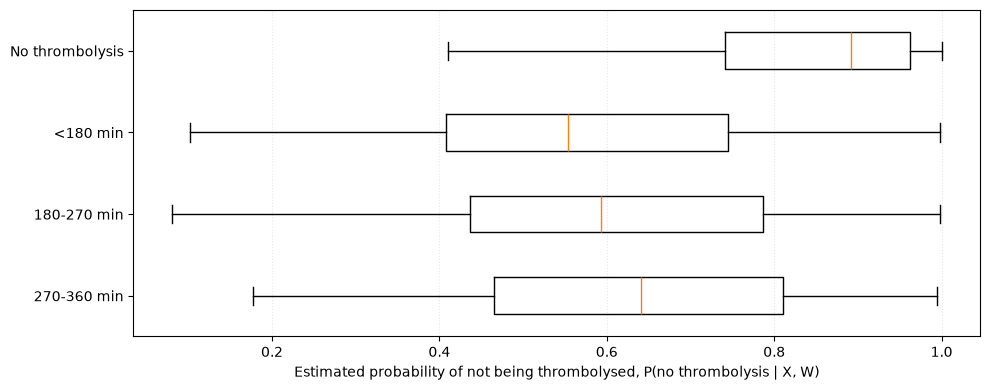

In [12]:
p_none = dr["p0"]
overlap = pd.DataFrame([
    {"treatment_group": g, "n": int(mask.sum()),
     "median P(no thrombolysis)": np.median(p_none[mask]),
     "% with P(no thrombolysis) < 0.05": 100 * (p_none[mask] < 0.05).mean(),
     "% with P(no thrombolysis) < 0.01": 100 * (p_none[mask] < 0.01).mean()}
    for g in [CONTROL_GROUP] + GROUP_ORDER
    for mask in [dr["group"] == g]
]).round(3)
display(overlap)

fig, ax = plt.subplots(figsize=(10, 4))
ax.boxplot([p_none[dr["group"] == g] for g in [CONTROL_GROUP] + GROUP_ORDER], vert=False, showfliers=False)
ax.set_yticklabels([CONTROL_GROUP] + GROUP_ORDER)
ax.invert_yaxis()
ax.set_xlabel("Estimated probability of not being thrombolysed, P(no thrombolysis | X, W)")
ax.grid(axis="x", alpha=0.3, linestyle=":")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_overlap.png", dpi=300)
plt.show()

**Results.**
* **Overlap for the ATT (main estimand) is good.**
  * Treated patients have a median probability of *not* being thrombolysed of 0.55–0.64.
  * **None** has a probability below 0.05, so every treated patient has comparable untreated patients.
  * As a result, the "Exclude P(no thrombolysis) < 0.05" sensitivity analysis (Section 10) excludes nobody.
* **Overlap for the ATE is much worse.** Many untreated patients have very low probabilities of thrombolysis in a given window, especially at 270–360 min (see the next table). The ATE is therefore reported only where positivity holds for most of the cohort.

# 6. Treatment effects

* **ATT** (main result): the AIPW effect in the patients who were thrombolysed, for each window and for all windows combined.
* **ATE:** the effect if everyone in the cohort were thrombolysed in that window. It is only reported where fewer than 20% of patients have a predicted probability of that window below 0.01.
* **Mean CATE in treated:** the simple average of the forest's individual estimates (no CI, because they share the same trees).

Effects are differences in the probability of a good outcome, in percentage points. The per-patient CATEs are saved to CSV.

In [13]:
effects = dr_effects(est, X, y, arm, data["stroke_severity"])
effects.to_csv(f"{OUTPUT_DIR}/{prefix}_effects.csv", index=False)

overall = effects[effects["nihss"] == "1-5"].set_index("treatment_group")
effects_table = pd.DataFrame({
    "n treated": overall["n_treated"],
    "ATT, % points (95% CI)": [fmt_pp(*r) for r in overall[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()],
    "ATE, % points (95% CI)": [fmt_pp(*aipw_ate(dr, g)) if g in GROUP_ORDER else "-" for g in overall.index],
    "% of cohort with P(window) < 0.01": [round(100 * (dr["p"][g] < PROPENSITY_CLIP).mean(), 1)
                                          if g in GROUP_ORDER else np.nan for g in overall.index],
    "Mean CATE in treated, % points": (100 * overall["mean_cate"]).round(1),
})
effects_table.to_csv(f"{OUTPUT_DIR}/{prefix}_effects_table.csv")

# Per-patient CATE for each patient's own window (vs no thrombolysis)
cate_df = data[X_FEATURES + ["treatment_group", "outcome_target"]].copy()
cate_df["cate"] = dr["own_theta"]
cate_df.to_csv(f"{OUTPUT_DIR}/{prefix}_causal_forest_cate_estimates.csv", index=True)
effects_table

,n treated,"ATT, % points (95% CI)","ATE, % points (95% CI)",% of cohort with P(window) < 0.01,"Mean CATE in treated, % points"
treatment_group,,,,,
All (≤360 min),13380,"5.0 (4.0, 6.0)",-,NaN,5.0
<180 min,7390,"6.3 (5.1, 7.6)","4.1 (2.3, 5.8)",14.4,6.4
180-270 min,5514,"3.5 (2.1, 4.8)","2.1 (0.1, 4.1)",13.6,3.5
270-360 min,476,"1.8 (-2.1, 5.6)",-,77.2,2.1


**Results.**
* **ATT.** Thrombolysis increased good outcome by 5.0 points (4.0 to 6.0) in treated patients. The effect fell with later treatment:
  * within 180 min: 6.3 (5.1 to 7.6);
  * at 180–270 min: 3.5 (2.1 to 4.8), about half the early effect;
  * at 270–360 min: 1.8 (−2.1 to 5.6). This is based on only 476 patients and cannot exclude no effect.
* **ATE.** The ATE is smaller than the ATT: 4.1 vs 6.3 within 180 min, and 2.1 vs 3.5 at 180–270 min.
  * Thrombolysis would therefore help the average mild-stroke patient less than it helped those who received it. This fits with clinicians mainly treating patients with higher NIHSS, who benefit most (Section 7).
  * The ATE is not reported for 270–360 min, because 77% of the cohort had a predicted probability below 0.01 of treatment in that window.
* **Mean CATE.** The forest's mean CATE in treated patients (5.0, 6.4, 3.5 and 2.1) is very close to the doubly robust ATT, so the forest and the AIPW correction agree.

## 6.1 Comparison with EconML's built-in doubly robust estimates

EconML also provides doubly robust ATT estimates (`att__inference`). These divide by unclipped treatment probabilities. They are shown here alongside the AIPW ATT used in this notebook, together with the smallest predicted probability of each treated patient's own treatment window.

In [14]:
builtin = []
arm_levels = sorted(np.unique(arm))
for k, level in enumerate(arm_levels):
    if level == BASELINE_ARM:
        continue
    group = CODE_TO_GROUP[level]
    builtin.append({
        "treatment_group": group,
        "EconML att__inference, % points": round(100 * float(np.ravel(est.att__inference(T=k).point_estimate)[k - 1]), 1),
        "AIPW ATT (clipped), % points": round(100 * float(overall.loc[group, "att"]), 1),
        "smallest P(own window) in treated": dr["p"][group][dr["group"] == group].min(),
    })
pd.DataFrame(builtin)

,treatment_group,"EconML att__inference, % points","AIPW ATT (clipped), % points",smallest P(own window) in treated
0,<180 min,1.5,6.3,0.000710
1,180-270 min,-2.1,3.5,0.000567
2,270-360 min,-123.8,1.8,0.000075


**Results.**
* EconML's built-in ATT estimates are implausible: 1.5, −2.1 and **−123.8** percentage points.
* This is because a few treated patients have extremely small estimated probabilities of the window they were actually treated in (as low as 0.00008 at 270–360 min). Dividing by these unclipped probabilities gives single patients huge weights.
* The clipped AIPW ATT used in this notebook is not affected, and it agrees with the forest's own mean CATE.

## 6.2 Plot of treatment effects

For each window and all windows combined: the AIPW ATT with 95% CI, and the forest's mean CATE in treated patients (no CI), in percentage points.

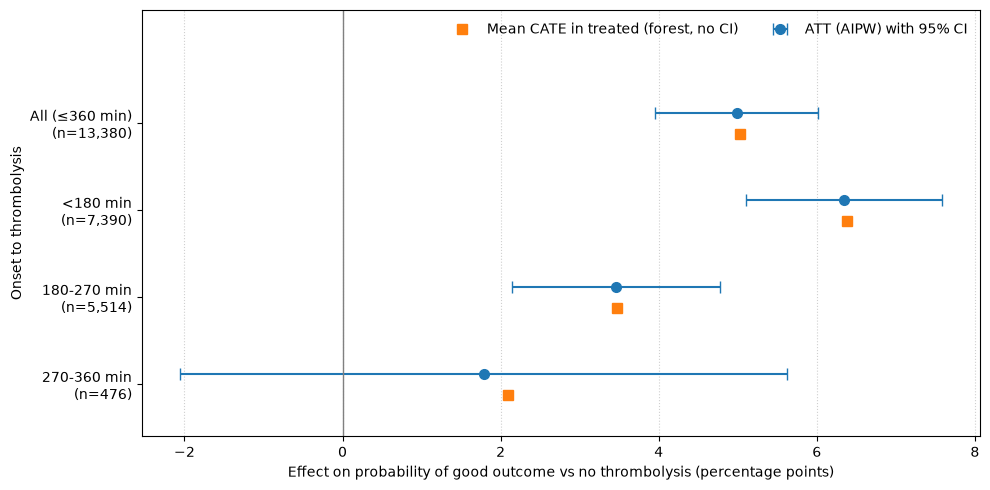

In [15]:
fig, ax = plt.subplots(figsize=(10, 5))
order = [ALL_TREATED] + GROUP_ORDER
ypos = np.arange(len(order))[::-1]
o = overall.reindex(order)
point = 100 * o["att"]
ax.errorbar(point, ypos + 0.12, xerr=[point - 100 * o["att_ci_lower"], 100 * o["att_ci_upper"] - point],
            fmt="o", color="#1f77b4", capsize=4, markersize=7, label="ATT (AIPW) with 95% CI")
ax.plot(100 * o["mean_cate"], ypos - 0.12, "s", color="#ff7f0e", markersize=7, label="Mean CATE in treated (forest, no CI)")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{g}\n(n={int(n):,})" for g, n in zip(order, o["n_treated"])])
ax.axvline(0, color="0.5", lw=1)
ax.set_xlabel("Effect on probability of good outcome vs no thrombolysis (percentage points)")
ax.set_ylabel("Onset to thrombolysis")
ax.grid(axis="x", linestyle=":", alpha=0.6)
ax.set_ylim(-0.6, len(order) + 0.3)  # leave space for the legend above the top row
ax.legend(loc="upper right", frameon=False, ncol=2)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_cate.png", dpi=300)
plt.show()

**Results.** The plot shows the pattern in the table. There is a clear benefit overall, within 180 min and at 180–270 min, and a wide CI at 270–360 min. The mean CATE lies close to the ATT in every window.

# 7. Effects by NIHSS score

Doubly robust ATT within each NIHSS score, for each treatment window and for all windows combined. The untreated proportion with a good outcome at each NIHSS score is shown for context. The table is followed by one panel per window.

In [16]:
by_nihss = effects[effects["nihss"] != "1-5"].copy()
untreated_good = (pd.Series(y[dr["group"] == CONTROL_GROUP])
                  .groupby(data["stroke_severity"].to_numpy()[dr["group"] == CONTROL_GROUP]).mean())
by_nihss["untreated_good_outcome"] = by_nihss["nihss"].astype(int).map(untreated_good)
by_nihss.to_csv(f"{OUTPUT_DIR}/{prefix}_cate_by_severity.csv", index=False)

nihss_table = (by_nihss.assign(att_publish=[fmt_pp(*r) for r in by_nihss[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()])
               .pivot(index="nihss", columns="treatment_group", values="att_publish")
               .reindex(columns=[ALL_TREATED] + GROUP_ORDER))
nihss_table["Untreated good outcome (%)"] = (100 * untreated_good).round(1).to_numpy()
nihss_table  # ATT, percentage points (95% CI)

treatment_group,All (≤360 min),<180 min,180-270 min,270-360 min,Untreated good outcome (%)
nihss,,,,,
1,"-2.1 (-4.8, 0.7)","-1.0 (-4.6, 2.7)","-2.6 (-6.5, 1.4)","-9.1 (-23.9, 5.7)",83.1
2,"0.2 (-1.7, 2.2)","0.5 (-2.1, 3.0)","0.4 (-2.3, 3.1)","-3.6 (-11.5, 4.4)",78.1
3,"5.3 (3.4, 7.2)","5.0 (2.7, 7.4)","5.9 (3.3, 8.4)","2.7 (-5.4, 10.9)",71.5
4,"5.9 (4.0, 7.9)","7.7 (5.4, 10.0)","3.5 (1.0, 6.0)","5.9 (-1.1, 13.0)",65.1
5,"7.1 (4.8, 9.3)","9.2 (6.6, 11.8)","4.3 (1.5, 7.1)","3.6 (-4.8, 11.9)",61.3


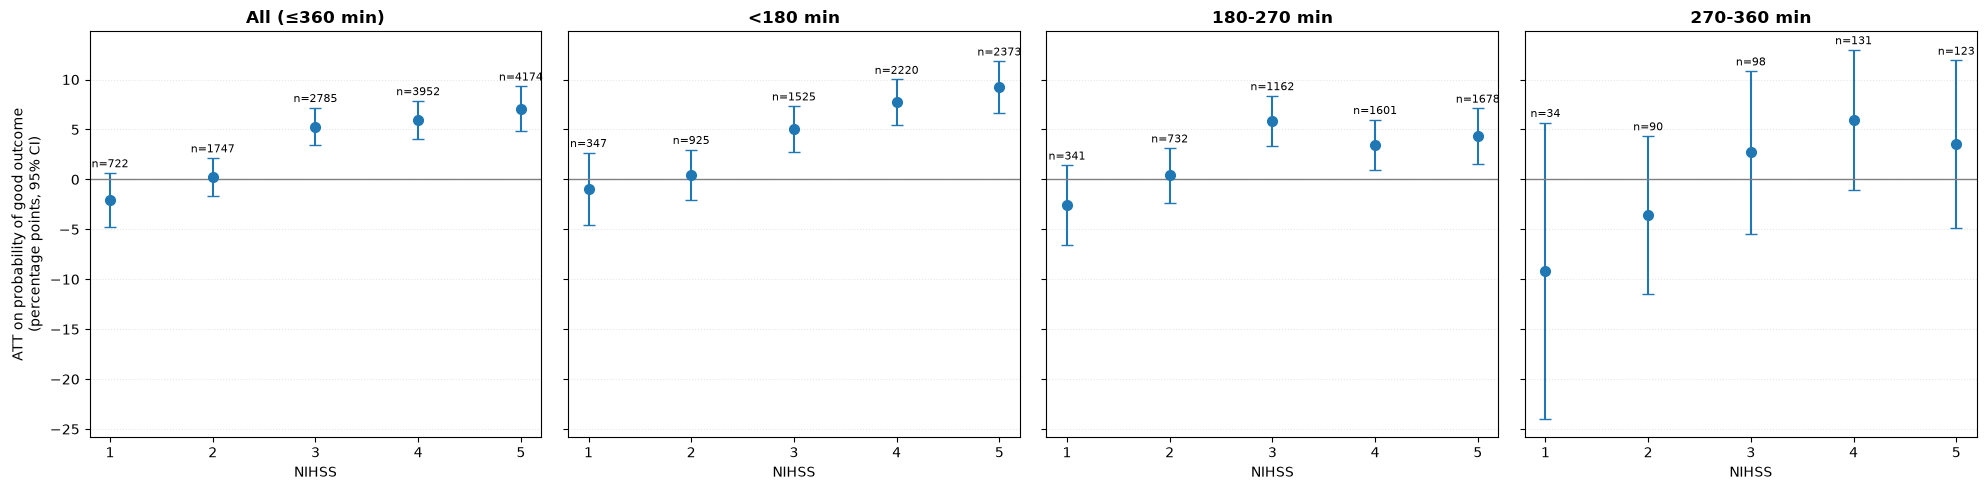

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, label in zip(axes, [ALL_TREATED] + GROUP_ORDER):
    d = by_nihss[by_nihss["treatment_group"] == label]
    xs = d["nihss"].astype(int).to_numpy()
    point = 100 * d["att"].to_numpy()
    ax.errorbar(xs, point, yerr=[point - 100 * d["att_ci_lower"], 100 * d["att_ci_upper"] - point],
                fmt="o", capsize=4, markersize=7, color="#1f77b4")
    for xi, yi, n in zip(xs, 100 * d["att_ci_upper"], d["n_treated"]):
        ax.annotate(f"n={n}", (xi, yi), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=8)
    ax.axhline(0, color="0.5", lw=1)
    ax.set_title(label, fontweight="bold")
    ax.set_xlabel("NIHSS")
    ax.set_xticks(NIHSS_VALUES)
    ax.grid(axis="y", alpha=0.3, linestyle=":")
axes[0].set_ylabel("ATT on probability of good outcome\n(percentage points, 95% CI)")
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_cate_by_severity.png", dpi=300)
plt.show()

**Results.**
* **Benefit by NIHSS.** The benefit rises steadily with NIHSS (all windows combined):
  * NIHSS 1: −2.1 (−4.8 to 0.7)
  * NIHSS 2: 0.2 (−1.7 to 2.2)
  * NIHSS 3: 5.3 (3.4 to 7.2)
  * NIHSS 4: 5.9 (4.0 to 7.9)
  * NIHSS 5: 7.1 (4.8 to 9.3)
* **No detectable benefit at NIHSS 1–2.** Untreated patients with NIHSS 1–2 have a good outcome 78–83% of the time, leaving little room for improvement. The negative point estimate at NIHSS 1 is not statistically significant.
* **Timing within NIHSS.**
  * Within 180 min the gradient is steeper, reaching 9.2 points (6.6 to 11.8) at NIHSS 5.
  * At 180–270 min the benefit at NIHSS 3–5 is 3.5–5.9 points.
  * At 270–360 min the CIs are too wide to draw conclusions at any NIHSS score.

## 7.1 Comparison with the matched target trial emulation

The matched target trial emulation (`4_target_trial_emulation/02_...`) estimates the same quantity, the effect in the treated. It uses exact matching on pre-stroke mRS, NIHSS, age and atrial fibrillation, with CIs from paired differences. Agreement between the two methods makes the results more credible. The comparison is shown by NIHSS (all windows) and by window (NIHSS 1–5), with a plot.

,NIHSS,Onset to thrombolysis,Causal forest ATT (95% CI),Matched TTE (95% CI),Difference (CF - TTE)
1,1,All (≤360 min),"-2.1 (-4.8, 0.7)","-0.3 (-4.0, 3.5)",-1.8
2,2,All (≤360 min),"0.2 (-1.7, 2.2)","0.9 (-1.6, 3.3)",-0.6
3,3,All (≤360 min),"5.3 (3.4, 7.2)","4.8 (2.7, 6.9)",0.5
4,4,All (≤360 min),"5.9 (4.0, 7.9)","6.6 (4.7, 8.5)",-0.6
5,5,All (≤360 min),"7.1 (4.8, 9.3)","8.5 (6.6, 10.5)",-1.4
0,1-5,All (≤360 min),"5.0 (4.0, 6.0)","5.7 (4.7, 6.7)",-0.7


,NIHSS,Onset to thrombolysis,Causal forest ATT (95% CI),Matched TTE (95% CI),Difference (CF - TTE)
0,1-5,All (≤360 min),"5.0 (4.0, 6.0)","5.7 (4.7, 6.7)",-0.7
6,1-5,<180 min,"6.3 (5.1, 7.6)","6.8 (5.4, 8.1)",-0.4
12,1-5,180-270 min,"3.5 (2.1, 4.8)","4.6 (3.0, 6.2)",-1.1
18,1-5,270-360 min,"1.8 (-2.1, 5.6)","2.1 (-3.1, 7.3)",-0.3


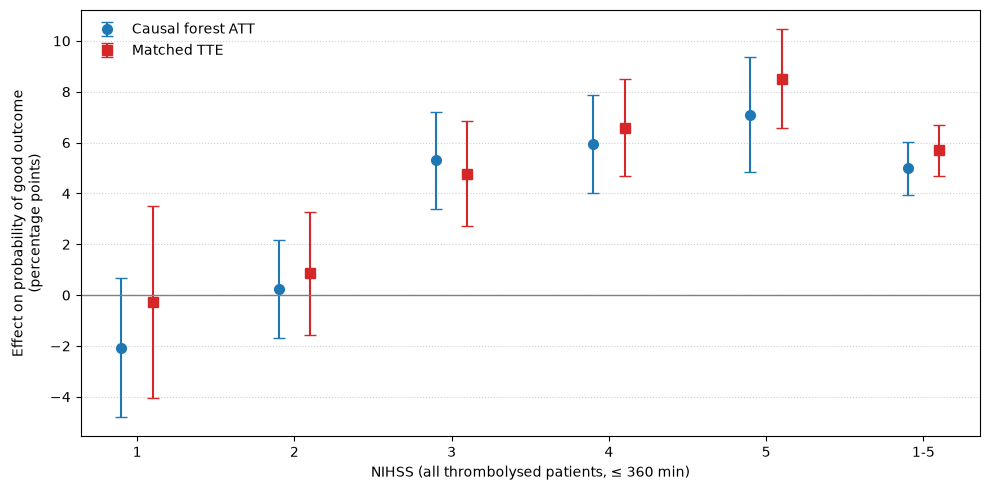

In [18]:
try:
    tte = pd.read_csv(TTE_SUMMARY_PATH, dtype={"nihss": str})
    comparison = effects.merge(
        tte[["nihss", "treatment_group", "difference", "difference_ci_lower", "difference_ci_upper"]],
        on=["nihss", "treatment_group"])
    comparison_table = pd.DataFrame({
        "NIHSS": comparison["nihss"],
        "Onset to thrombolysis": comparison["treatment_group"],
        "Causal forest ATT (95% CI)": [fmt_pp(*r) for r in comparison[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()],
        "Matched TTE (95% CI)": [fmt_pp(*r) for r in comparison[["difference", "difference_ci_lower", "difference_ci_upper"]].to_numpy()],
        "Difference (CF - TTE)": (100 * (comparison["att"] - comparison["difference"])).round(1),
    })
    display(comparison_table[comparison_table["Onset to thrombolysis"] == ALL_TREATED]
            .sort_values("NIHSS", key=lambda s: s.map({k: i for i, k in enumerate(NIHSS_LABELS[1:] + ["1-5"])})))
    display(comparison_table[comparison_table["NIHSS"] == "1-5"])

    fig, ax = plt.subplots(figsize=(10, 5))
    c = comparison[comparison["treatment_group"] == ALL_TREATED].set_index("nihss").reindex(NIHSS_LABELS[1:] + ["1-5"])
    xs = np.arange(len(c))
    for offset, cols, label, colour, marker in [
            (-0.1, ("att", "att_ci_lower", "att_ci_upper"), "Causal forest ATT", "#1f77b4", "o"),
            (0.1, ("difference", "difference_ci_lower", "difference_ci_upper"), "Matched TTE", "#d62728", "s")]:
        point = 100 * c[cols[0]]
        ax.errorbar(xs + offset, point, yerr=[point - 100 * c[cols[1]], 100 * c[cols[2]] - point],
                    fmt=marker, color=colour, capsize=4, markersize=7, label=label)
    ax.set_xticks(xs)
    ax.set_xticklabels(c.index)
    ax.set_xlabel("NIHSS (all thrombolysed patients, ≤ 360 min)")
    ax.set_ylabel("Effect on probability of good outcome\n(percentage points)")
    ax.axhline(0, color="0.5", lw=1)
    ax.grid(axis="y", linestyle=":", alpha=0.6)
    ax.legend(frameon=False)
    plt.tight_layout()
    plt.savefig(f"{OUTPUT_DIR}/{prefix}_vs_target_trial.png", dpi=300)
    plt.show()
except FileNotFoundError:
    print(f"Target trial emulation results not found at {TTE_SUMMARY_PATH}; run that notebook first.")

**Results.**
* **The two methods agree closely**, and every causal forest CI overlaps the TTE CI:
  * by NIHSS, the differences (causal forest − TTE) are −1.8, −0.6, +0.5, −0.6 and −1.4 points;
  * overall: 5.0 vs 5.7;
  * by window: 6.3 vs 6.8 (< 180 min), 3.5 vs 4.6 (180–270 min) and 1.8 vs 2.1 (270–360 min).
* **Same pattern in both methods:** no benefit at NIHSS 1–2, clear benefit at NIHSS 3–5, and a smaller benefit with later treatment.
* **The causal forest is slightly lower in most comparisons.** It adjusts for more characteristics than the exact matching (including stroke team, comorbidities and ethnicity), which may remove a small amount of residual confounding.
* **What the agreement shows.** The methods differ in their modelling assumptions but share the assumption of no unmeasured confounding. Their agreement shows robustness to how measured confounders are handled, not to unmeasured confounding.

# 8. Effects in subgroups of patients treated within 270 minutes

For patients thrombolysed within 270 minutes (< 180 and 180–270 min combined), the doubly robust ATT is estimated within each level of each patient characteristic. Subgroups with fewer than `MIN_SUBGROUP_TREATED` (30) treated patients are not shown.

Whether the effect differs between levels of a characteristic is tested with a chi-square test of homogeneity. For K levels, Q = Σ wₖ (ATTₖ − weighted mean)² with wₖ = 1 / SEₖ², compared with a χ² distribution on K − 1 degrees of freedom. P values are not adjusted for multiple comparisons.

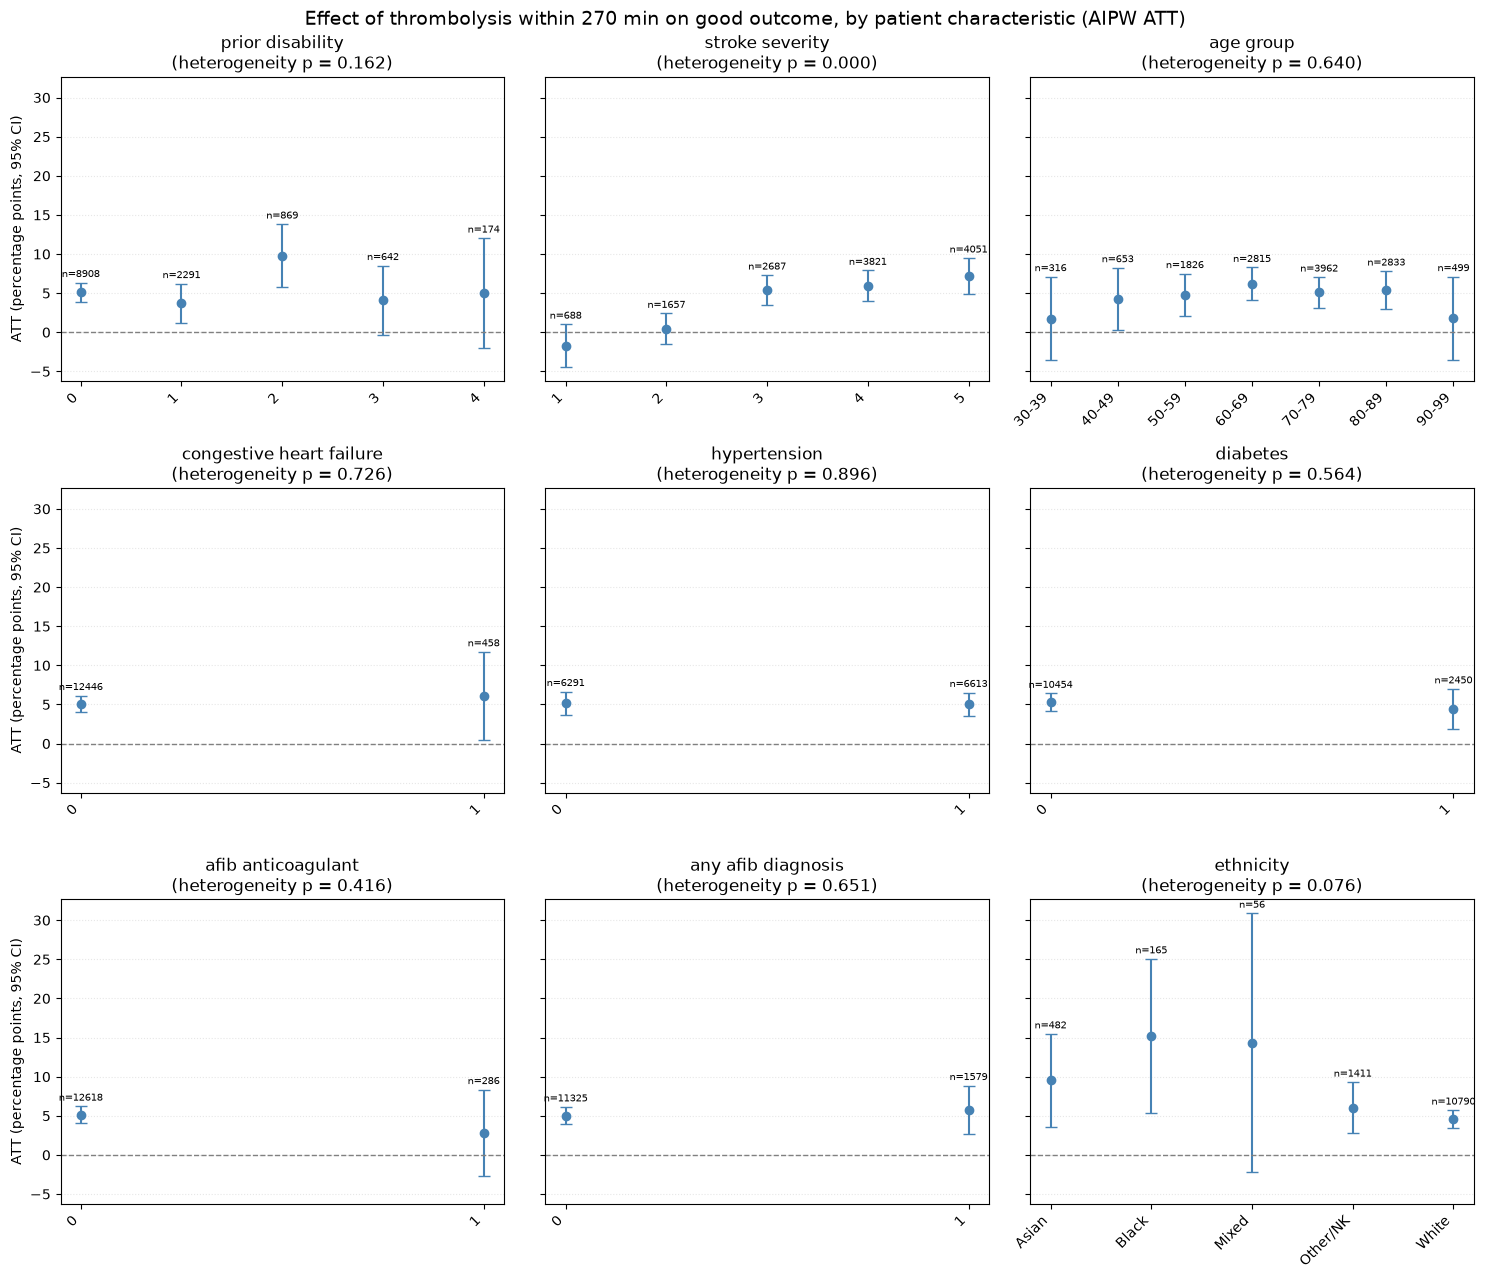

,feature,levels,Q,df,p_value
0,prior_disability,5,6.551,4,0.162
1,stroke_severity,5,42.594,4,0.000
2,age_group,7,4.271,6,0.640
3,congestive_heart_failure,2,0.122,1,0.726
4,hypertension,2,0.017,1,0.896
5,diabetes,2,0.333,1,0.564
6,afib_anticoagulant,2,0.660,1,0.416
7,any_afib_diagnosis,2,0.204,1,0.651
8,ethnicity,5,8.468,4,0.076


In [19]:
UNDER_270 = ["<180 min", "180-270 min"]
data["age_group"] = pd.cut(data["age"], bins=np.arange(0, 110, 10), right=False)
SUBGROUP_FEATURES = ["prior_disability", "stroke_severity", "age_group", "congestive_heart_failure",
                     "hypertension", "diabetes", "afib_anticoagulant", "any_afib_diagnosis", "ethnicity"]

subgroup_rows, homogeneity = [], []
for feature in SUBGROUP_FEATURES:
    values = data[feature].to_numpy()
    levels = sorted(pd.Series(values).dropna().unique(), key=lambda v: v.left if isinstance(v, pd.Interval) else v)
    atts, ses = [], []
    for level in levels:
        att, lo, hi, n_treated = aipw_att(dr, UNDER_270, subgroup=(values == level))
        if n_treated < MIN_SUBGROUP_TREATED or np.isnan(att):
            continue
        label = f"{int(level.left)}-{int(level.right) - 1}" if isinstance(level, pd.Interval) else (
            str(int(level)) if isinstance(level, (int, float, np.integer, np.floating)) and float(level).is_integer() else str(level))
        subgroup_rows.append({"feature": feature, "level": label, "n_treated": n_treated,
                              "att": att, "att_ci_lower": lo, "att_ci_upper": hi})
        atts.append(att)
        ses.append((hi - lo) / (2 * 1.96))
    if len(atts) > 1:
        w = 1 / np.square(ses)
        q = float(np.sum(w * np.square(np.array(atts) - np.sum(w * atts) / np.sum(w))))
        homogeneity.append({"feature": feature, "levels": len(atts), "Q": q, "df": len(atts) - 1,
                            "p_value": stats.chi2.sf(q, len(atts) - 1)})
subgroups = pd.DataFrame(subgroup_rows)
subgroups.to_csv(f"{OUTPUT_DIR}/{prefix}_subgroup_att_treated_under_270_min.csv", index=False)
homogeneity = pd.DataFrame(homogeneity)
homogeneity.to_csv(f"{OUTPUT_DIR}/{prefix}_subgroup_homogeneity_tests.csv", index=False)

fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharey=True)
for ax, feature in zip(axes.flat, SUBGROUP_FEATURES):
    d = subgroups[subgroups["feature"] == feature]
    xs = np.arange(len(d))
    point = 100 * d["att"].to_numpy()
    ax.errorbar(xs, point, yerr=[point - 100 * d["att_ci_lower"], 100 * d["att_ci_upper"] - point],
                fmt="o", capsize=4, markersize=6, color="steelblue")
    for xi, yi, n in zip(xs, 100 * d["att_ci_upper"], d["n_treated"]):
        ax.annotate(f"n={n}", (xi, yi), textcoords="offset points", xytext=(0, 4), ha="center", fontsize=7)
    p = homogeneity.loc[homogeneity["feature"] == feature, "p_value"]
    ax.set_title(f"{feature.replace('_', ' ')}" + (f"\n(heterogeneity p = {p.iloc[0]:.3f})" if len(p) else ""))
    ax.set_xticks(xs)
    ax.set_xticklabels(d["level"], rotation=45, ha="right")
    ax.axhline(0, color="0.5", lw=1, linestyle="--")
    ax.grid(axis="y", alpha=0.3, linestyle=":")
for ax in axes[:, 0]:
    ax.set_ylabel("ATT (percentage points, 95% CI)")
fig.suptitle(f"Effect of thrombolysis within 270 min on good outcome, by patient characteristic (AIPW ATT)", fontsize=14)
plt.tight_layout()
plt.savefig(f"{OUTPUT_DIR}/{prefix}_subgroup_att_treated_under_270_min.png", dpi=300, bbox_inches="tight")
plt.show()
homogeneity.round(3)

**Results (patients treated within 270 min):**
* **Stroke severity** is the only characteristic with clear evidence that the effect varies (p < 0.001): −1.7, 0.4, 5.4, 6.0 and 7.2 points for NIHSS 1–5.
* **Ethnicity** shows weak evidence of variation (p = 0.076):
  * Point estimates are larger in Asian (9.5, n = 482), Black (15.2, n = 165) and Mixed (14.4, n = 56) patients than in White patients (4.6).
  * These groups are small, the CIs are wide, and the p value is not adjusted for multiple testing. This is hypothesis-generating only.
* **No evidence of variation** by:
  * pre-stroke disability (p = 0.16);
  * age (p = 0.64), with a similar benefit from age 40 to 89 (4.3–6.2 points);
  * heart failure, hypertension, diabetes or atrial fibrillation (all p > 0.4).
* There is a benefit in patients with some pre-stroke disability (mRS 1: 3.7 points; mRS 2: 9.8 points).

# 9. Relative effects, first-stage performance and a test of heterogeneity

* **Relative effects:** the risk ratio in the treated is the observed proportion with a good outcome divided by the doubly robust estimate of that proportion without thrombolysis. It is reported for each window and all windows combined, and for all windows combined within each NIHSS score. The 95% CIs come from the influence function, so they are consistent with the ATT CIs (TARGET item 13).
* **First-stage performance:** bootstrap 95% CIs for the ROC AUCs; calibration of the first-stage outcome model by decile, with calibration intercept and slope (TRIPOD items 10d and 16).
* **Best linear predictor (BLP) test:** for each window, among patients with adequate overlap, the doubly robust effect is regressed on the forest's out-of-bag CATE.
  * A slope above zero means the forest detects real differences in benefit between patients.
  * A slope near 1 means its estimates are well calibrated.

Results are also printed as LaTeX rows for the paper.

,treatment_group,nihss,n_treated,treated_proportion,untreated_proportion_dr,att,rr,rr_ci_lower,rr_ci_upper
0,All (≤360 min),1-5,13380,0.774,0.725,0.050,1.069,1.054,1.084
1,<180 min,1-5,7390,0.787,0.724,0.063,1.088,1.070,1.106
2,180-270 min,1-5,5514,0.758,0.723,0.035,1.048,1.030,1.067
3,270-360 min,1-5,476,0.771,0.753,0.018,1.024,0.974,1.076
4,All (≤360 min),1,722,0.846,0.867,-0.021,0.976,0.945,1.008
5,All (≤360 min),2,1747,0.837,0.835,0.002,1.003,0.980,1.026
6,All (≤360 min),3,2785,0.815,0.762,0.053,1.070,1.044,1.096
7,All (≤360 min),4,3952,0.764,0.705,0.059,1.084,1.056,1.114
8,All (≤360 min),5,4174,0.718,0.648,0.071,1.110,1.073,1.148


,auc,auc_ci_lower,auc_ci_upper
Outcome (good outcome),0.716,0.710,0.721
Treatment: No thrombolysis,0.806,0.803,0.810
Treatment: <180 min,0.788,0.782,0.792
Treatment: 180-270 min,0.739,0.735,0.743
Treatment: 270-360 min,0.696,0.678,0.710


,estimate,ci_lower,ci_upper
Calibration intercept,-0.003,-0.020,0.008
Calibration slope,0.880,0.853,0.903


,n,predicted,observed
decile,,,
1,5839,0.401,0.440
2,5839,0.567,0.590
3,5839,0.650,0.658
4,5839,0.711,0.706
5,5839,0.761,0.745
6,5839,0.805,0.795
7,5838,0.842,0.835
8,5839,0.875,0.863
9,5839,0.908,0.893


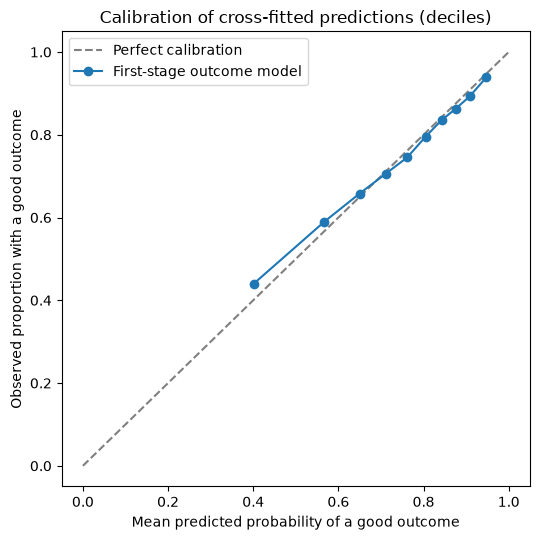

CATE used for the BLP test: out-of-bag


,treatment_group,n_in_overlap,n_treated_in_overlap,mean_effect,mean_effect_se,blp_slope,blp_slope_ci_lower,blp_slope_ci_upper,p_value_slope_gt_0
0,<180 min,30460,6853,0.046,0.007,0.070,-0.149,0.289,0.265
1,180-270 min,27179,4845,0.027,0.008,0.184,-0.037,0.406,0.052
2,270-360 min,1900,80,0.047,0.026,0.259,-0.159,0.677,0.112


% ---- Relative effects: group & NIHSS & n & treated % & untreated % (DR) & RR (95% CI) ----
All (≤360 min) & 1-5 & 13,380 & 77.4 & 72.5 & 1.07 (1.05--1.08) \\
<180 min & 1-5 & 7,390 & 78.7 & 72.4 & 1.09 (1.07--1.11) \\
180-270 min & 1-5 & 5,514 & 75.8 & 72.3 & 1.05 (1.03--1.07) \\
270-360 min & 1-5 & 476 & 77.1 & 75.3 & 1.02 (0.97--1.08) \\
All (≤360 min) & 1 & 722 & 84.6 & 86.7 & 0.98 (0.95--1.01) \\
All (≤360 min) & 2 & 1,747 & 83.7 & 83.5 & 1.00 (0.98--1.03) \\
All (≤360 min) & 3 & 2,785 & 81.5 & 76.2 & 1.07 (1.04--1.10) \\
All (≤360 min) & 4 & 3,952 & 76.4 & 70.5 & 1.08 (1.06--1.11) \\
All (≤360 min) & 5 & 4,174 & 71.8 & 64.8 & 1.11 (1.07--1.15) \\
% ---- First-stage AUC (95% CI, bootstrap) ----
% Outcome (good outcome): 0.716 (0.710--0.721)
% Treatment: No thrombolysis: 0.806 (0.803--0.810)
% Treatment: <180 min: 0.788 (0.782--0.792)
% Treatment: 180-270 min: 0.739 (0.735--0.743)
% Treatment: 270-360 min: 0.696 (0.678--0.710)
% ---- Outcome model calibration ----
% Calibration in

In [20]:
# Additional reporting for the causal forest (TARGET item 13; TRIPOD items 10d and 16):
# 1. Relative effects: risk ratio (RR) in the treated, observed proportion with a good outcome divided by the
#    doubly robust estimate of that proportion without thrombolysis, with 95% CIs from the influence function
#    (delta method on the log scale), using the same clipped AIPW estimator as the ATT. Reported for each
#    window and all windows combined, and for all windows combined within each NIHSS score.
# 2. 95% CIs for first-stage ROC AUCs from N_BOOT bootstrap samples of the cross-fitted predictions.
# 3. Calibration of the first-stage outcome model: by decile, and calibration intercept and slope.
# 4. Heterogeneity: best linear predictor (BLP) test for each window against no thrombolysis.
#    Among patients thrombolysed in the window or not thrombolysed, with conditional probability of the
#    window between 0.05 and 0.95, the doubly robust pseudo-outcome is regressed on the centred CATE.
#    A slope above zero shows that the forest detects real differences in benefit between patients;
#    a slope near 1 shows that those differences are well calibrated.

import math

from IPython.display import display
from sklearn.linear_model import LogisticRegression

N_BOOT = 30
OVERLAP_BOUNDS = (0.05, 0.95)
n_patients = len(y)
nihss_array = data["stroke_severity"].to_numpy()


def aipw_risk_ratio(dr, treat_groups, subgroup=None, clip=PROPENSITY_CLIP):
    """Risk ratio in the treated with an influence-function 95% CI (same AIPW estimator as aipw_att)."""
    n = len(dr["y"])
    s = np.ones(n) if subgroup is None else np.asarray(subgroup, dtype=float)
    treated = np.isin(dr["group"], treat_groups) * s
    control = (dr["group"] == CONTROL_GROUP) * s
    odds = np.clip(dr["p"][treat_groups].sum(axis=1).to_numpy(), clip, 1) / np.clip(dr["p0"], clip, 1)
    resid0 = dr["y"] - dr["mu0"]
    p1 = (treated * dr["y"]).sum() / treated.sum()  # observed proportion with a good outcome
    att = (treated * resid0 - control * odds * resid0).sum() / treated.sum()
    q0 = p1 - att  # doubly robust estimate of that proportion without thrombolysis
    psi_p1 = treated * (dr["y"] - p1) / treated.mean()
    psi_att = (treated * (resid0 - att) - control * odds * resid0) / treated.mean()
    psi_log_rr = psi_p1 / p1 - (psi_p1 - psi_att) / q0
    se_log_rr = psi_log_rr.std(ddof=1) / np.sqrt(n)
    rr = p1 / q0
    return {"n_treated": int(treated.sum()), "treated_proportion": p1, "untreated_proportion_dr": q0,
            "att": att, "rr": rr, "rr_ci_lower": np.exp(np.log(rr) - 1.96 * se_log_rr),
            "rr_ci_upper": np.exp(np.log(rr) + 1.96 * se_log_rr)}


# 1. Risk ratios
rr_rows = [{"treatment_group": label, "nihss": "1-5", **aipw_risk_ratio(dr, groups)}
           for label, groups in TREATMENT_SETS.items()]
rr_rows += [{"treatment_group": ALL_TREATED, "nihss": str(n),
             **aipw_risk_ratio(dr, GROUP_ORDER, nihss_array == n)} for n in NIHSS_VALUES]
relative_effects = pd.DataFrame(rr_rows)
relative_effects.to_csv(f"{OUTPUT_DIR}/{prefix}_relative_effects.csv", index=False)
display(relative_effects.round(3))


def calibration_intercept_slope(y_true, prob):
    """Calibration intercept (slope fixed at 1) and calibration slope on the logit scale."""
    prob = np.clip(prob, 1e-6, 1 - 1e-6)
    logit = np.log(prob / (1 - prob))
    slope = LogisticRegression(C=1e12, max_iter=1000).fit(logit.reshape(-1, 1), y_true).coef_[0, 0]
    a = 0.0
    for _ in range(50):
        p = 1 / (1 + np.exp(-(a + logit)))
        a += (y_true - p).sum() / (p * (1 - p)).sum()
    return a, slope


# 2 and 3. Bootstrap CIs for AUCs and calibration
m_hat = np.asarray(dr["m"])
propensity = dr["p"].copy()
propensity.insert(0, CONTROL_GROUP, dr["p0"])
model_predictions = {"Outcome (good outcome)": (y, m_hat)}
for group in [CONTROL_GROUP] + GROUP_ORDER:
    model_predictions[f"Treatment: {group}"] = ((dr["group"] == group).astype(int), propensity[group].to_numpy())

boot_rng = np.random.default_rng(SEED)
point_auc = {name: roc_auc_score(t, p) for name, (t, p) in model_predictions.items()}
point_cal = calibration_intercept_slope(y, m_hat)
boot_auc, boot_cal = [], []
for _ in range(N_BOOT):
    i = boot_rng.integers(0, n_patients, n_patients)
    boot_auc.append({name: roc_auc_score(t[i], p[i]) for name, (t, p) in model_predictions.items()})
    boot_cal.append(calibration_intercept_slope(y[i], m_hat[i]))
boot_auc, boot_cal = pd.DataFrame(boot_auc), np.array(boot_cal)

first_stage_performance = pd.DataFrame({
    "auc": pd.Series(point_auc),
    "auc_ci_lower": boot_auc.quantile(0.025),
    "auc_ci_upper": boot_auc.quantile(0.975),
})
first_stage_performance.to_csv(f"{OUTPUT_DIR}/{prefix}_first_stage_auc_bootstrap.csv")
display(first_stage_performance.round(3))

outcome_calibration = pd.DataFrame({
    "estimate": point_cal,
    "ci_lower": np.percentile(boot_cal, 2.5, axis=0),
    "ci_upper": np.percentile(boot_cal, 97.5, axis=0),
}, index=["Calibration intercept", "Calibration slope"])
decile = pd.qcut(m_hat, 10, labels=False, duplicates="drop")
outcome_calibration_deciles = (
    pd.DataFrame({"decile": decile + 1, "predicted": m_hat, "observed": y})
    .groupby("decile").agg(n=("observed", "size"), predicted=("predicted", "mean"),
                           observed=("observed", "mean")))
outcome_calibration.to_csv(f"{OUTPUT_DIR}/{prefix}_outcome_calibration.csv")
outcome_calibration_deciles.to_csv(f"{OUTPUT_DIR}/{prefix}_outcome_calibration_deciles.csv")
display(outcome_calibration.round(3))
display(outcome_calibration_deciles.round(3))

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Perfect calibration")
ax.plot(outcome_calibration_deciles["predicted"], outcome_calibration_deciles["observed"], "o-",
        label="First-stage outcome model")
ax.set_xlabel("Mean predicted probability of a good outcome")
ax.set_ylabel("Observed proportion with a good outcome")
ax.set_title("Calibration of cross-fitted predictions (deciles)")
ax.legend()
fig.tight_layout()
fig.savefig(f"{OUTPUT_DIR}/{prefix}_outcome_calibration.png", dpi=300)
plt.show()

# 4. Best linear predictor test of heterogeneity
theta_all = dr["theta"].to_numpy()
try:  # out-of-bag CATE, so that each patient's estimate comes from trees not trained on them
    theta_blp = np.asarray(est.model_final_.oob_predict(np.asarray(X))).reshape(n_patients, -1)
    if theta_blp.shape[1] != theta_all.shape[1]:
        raise ValueError("unexpected shape")
    cate_source = "out-of-bag"
except Exception as error:
    theta_blp, cate_source = theta_all, f"in-sample honest forest ({type(error).__name__})"
print("CATE used for the BLP test:", cate_source)


def ols_hc1(outcome, design):
    """OLS coefficients with heteroskedasticity-robust (HC1) standard errors."""
    beta, *_ = np.linalg.lstsq(design, outcome, rcond=None)
    resid = outcome - design @ beta
    n, k = design.shape
    bread = np.linalg.inv(design.T @ design)
    meat = (design * resid[:, None] ** 2).T @ design
    cov = bread @ meat @ bread * n / (n - k)
    return beta, np.sqrt(np.diag(cov))


blp_rows = []
mu0_hat, p0_hat = np.asarray(dr["mu0"]), np.asarray(dr["p0"])
for j, group in enumerate(dr["theta"].columns):
    is_j = dr["group"] == group
    p_j = dr["p"][group].to_numpy()
    e = p_j / (p_j + p0_hat)  # probability of the window, given the window or no thrombolysis
    keep = (is_j | (dr["group"] == CONTROL_GROUP)) & (e >= OVERLAP_BOUNDS[0]) & (e <= OVERLAP_BOUNDS[1])
    tau = theta_blp[keep, j]
    mu0_k, e_k, y_k, t_k = mu0_hat[keep], e[keep], y[keep], is_j[keep].astype(float)
    pseudo = tau + t_k * (y_k - mu0_k - tau) / e_k - (1 - t_k) * (y_k - mu0_k) / (1 - e_k)
    if tau.std() < 1e-12:  # no variation in the CATE: slope not defined
        beta = np.array([pseudo.mean(), np.nan])
        se = np.array([pseudo.std(ddof=1) / np.sqrt(len(pseudo)), np.nan])
    else:
        design = np.column_stack([np.ones(keep.sum()), tau - tau.mean()])
        beta, se = ols_hc1(pseudo, design)
    z = beta[1] / se[1]
    blp_rows.append({
        "treatment_group": group, "n_in_overlap": int(keep.sum()),
        "n_treated_in_overlap": int(t_k.sum()),
        "mean_effect": beta[0], "mean_effect_se": se[0],
        "blp_slope": beta[1], "blp_slope_ci_lower": beta[1] - 1.96 * se[1],
        "blp_slope_ci_upper": beta[1] + 1.96 * se[1],
        "p_value_slope_gt_0": 0.5 * math.erfc(z / math.sqrt(2)),
    })
blp_tests = pd.DataFrame(blp_rows)
blp_tests.to_csv(f"{OUTPUT_DIR}/{prefix}_blp_heterogeneity_test.csv", index=False)
display(blp_tests.round(3))

# LaTeX rows for the supplement
print("% ---- Relative effects: group & NIHSS & n & treated % & untreated % (DR) & RR (95% CI) ----")
for _, r in relative_effects.iterrows():
    print(f"{r['treatment_group']} & {r['nihss']} & {r['n_treated']:,} & {100 * r['treated_proportion']:.1f} & "
          f"{100 * r['untreated_proportion_dr']:.1f} & {r['rr']:.2f} ({r['rr_ci_lower']:.2f}--{r['rr_ci_upper']:.2f}) \\\\")
print("% ---- First-stage AUC (95% CI, bootstrap) ----")
for name, r in first_stage_performance.iterrows():
    print(f"% {name}: {r['auc']:.3f} ({r['auc_ci_lower']:.3f}--{r['auc_ci_upper']:.3f})")
print("% ---- Outcome model calibration ----")
for name, r in outcome_calibration.iterrows():
    print(f"% {name}: {r['estimate']:.3f} ({r['ci_lower']:.3f}--{r['ci_upper']:.3f})")
for d, r in outcome_calibration_deciles.iterrows():
    print(f"{d} & {int(r['n']):,} & {r['predicted']:.3f} & {r['observed']:.3f} \\\\")
print(f"% ---- BLP heterogeneity test (CATE: {cate_source}) ----")
for _, r in blp_tests.iterrows():
    print(f"{r['treatment_group']} & {r['n_in_overlap']:,} & {r['n_treated_in_overlap']:,} & "
          f"{r['blp_slope']:.2f} ({r['blp_slope_ci_lower']:.2f}--{r['blp_slope_ci_upper']:.2f}) & "
          f"{r['p_value_slope_gt_0']:.3f} \\\\")

**Results.**

**Risk ratios in the treated:**

| Group | NIHSS | n treated | Good outcome, treated | Without thrombolysis (DR estimate) | RR (95% CI) |
|---|---|---|---|---|---|
| All (≤ 360 min) | 1–5 | 13,380 | 77.4% | 72.5% | 1.07 (1.05 to 1.08) |
| < 180 min | 1–5 | 7,390 | 78.7% | 72.4% | 1.09 (1.07 to 1.11) |
| 180–270 min | 1–5 | 5,514 | 75.8% | 72.3% | 1.05 (1.03 to 1.07) |
| 270–360 min | 1–5 | 476 | 77.1% | 75.3% | 1.02 (0.97 to 1.08) |
| All (≤ 360 min) | 1 | 722 | 84.6% | 86.7% | 0.98 (0.95 to 1.01) |
| All (≤ 360 min) | 2 | 1,747 | 83.7% | 83.5% | 1.00 (0.98 to 1.03) |
| All (≤ 360 min) | 3 | 2,785 | 81.5% | 76.2% | 1.07 (1.04 to 1.10) |
| All (≤ 360 min) | 4 | 3,952 | 76.4% | 70.5% | 1.08 (1.06 to 1.11) |
| All (≤ 360 min) | 5 | 4,174 | 71.8% | 64.8% | 1.11 (1.07 to 1.15) |

Relative effects are small because good outcome is common in mild stroke. They follow the same pattern as the ATT.

**First-stage performance:**
* **AUCs** are precisely estimated:
  * outcome model: 0.716 (0.710 to 0.721);
  * treatment model: 0.806 (0.803 to 0.810) for no thrombolysis, 0.788 for < 180 min, 0.739 for 180–270 min and 0.696 (0.678 to 0.710) for 270–360 min.
* **Calibration of the outcome model.**
  * Calibration-in-the-large is good: intercept −0.003 (−0.020 to 0.008).
  * The slope is 0.88 (0.85 to 0.90), so predictions are somewhat too extreme. In the lowest decile, 40.1% was predicted against 44.0% observed; in the highest, 94.7% against 93.9%. The middle deciles agree within about 1.5 points.
  * The doubly robust ATT corrects the outcome model's predictions with the treatment model, so moderate miscalibration of either model has only a second-order effect on it.

**Best linear predictor (BLP) test**, among patients with a probability of the window between 0.05 and 0.95:

| Window | Patients in overlap (treated) | BLP slope (95% CI) | p (slope > 0) |
|---|---|---|---|
| < 180 min | 30,460 (6,853) | 0.07 (−0.15 to 0.29) | 0.27 |
| 180–270 min | 27,179 (4,845) | 0.18 (−0.04 to 0.41) | 0.052 |
| 270–360 min | 1,900 (80) | 0.26 (−0.16 to 0.68) | 0.11 |

* The slopes are well below 1 and not clearly above 0. The forest's individual-level CATEs therefore carry little *calibrated* information about which patients benefit more, beyond the average effect.
* This does not contradict the clear variation by NIHSS (Section 7). That comes from doubly robust estimates within prespecified subgroups, which do not rely on the forest ranking individual patients correctly. Variation in benefit is therefore reported as subgroup ATTs rather than individual CATEs.

# 10. Sensitivity analyses

This section tests how far the results depend on analytic choices and on the assumption of no unmeasured confounding:

* **10.1 Alternative specifications:** the whole model is refitted with **one** change at a time.
* **10.2 Forest plot** of those refits.
* **10.3 E-values** for unmeasured confounding.
* **10.4 Sensemakr** robustness values and benchmark bounds.
* **10.5 Leave-one-out** analysis of the main confounders.

## 10.1 Alternative specifications

Each refit reports the AIPW ATT for each window, all windows combined, and each NIHSS score (all windows combined).

| Category | Analysis | Why |
|---|---|---|
| Model specification | Categorical indices calculated separately for X and W ("Original categorical indices") | Stroke team is then treated as a numeric code and a copy of pre-stroke mRS as categorical. Tests sensitivity to the categorical encoding. |
| Confounders | Without stroke team | Tests how much adjustment for hospital practice matters. |
| Confounders | Also adjust for onset-to-scan time and year | Onset-to-scan time strongly predicts how soon thrombolysis can be given; year captures changes in practice over time. |
| Overlap | Exclude patients with P(no thrombolysis) < 0.05 | Removes patients with no comparable untreated patients. |
| First stage | Smaller LightGBM models (200 trees, 15 leaves) | Tests sensitivity to first-stage model complexity. |
| Forest | Minimum leaf size 50 | Tests sensitivity to forest settings. |
| Cross-fitting | Folds grouped by stroke team | Each team's patients are predicted by models trained on other teams. |
| Cohort | Arrival within 180 min | Patients arriving later in the 4-hour window have less time to be treated. |
| Cohort | All teams / teams with at least 20 thrombolyses | Tests the team thrombolysis-volume restriction (at least 10). |
| Outcome | mRS 0–2 only; mRS 0–1 only; mRS 0–1 or no worse than pre-stroke; mRS 0–3 or no worse than pre-stroke | Tests the good-outcome definition. mRS 0–1 (excellent outcome) is the usual outcome in trials of mild stroke; mRS 0–3 is more lenient. |
| Random seed | 3 other seeds | Variation from random cross-fitting splits, subsampling and the forest. |

Each refit takes about as long as the primary fit (Section 4). Results are saved to CSV as they are produced. The first cell runs the refits, and the second tabulates the ATT (percentage points, 95% CI) by analysis.

In [21]:
# Original categorical indices: X-relative for the outcome model, W-relative for the treatment model
X_tmp, W_tmp, *_ = build_matrices(data)
original_cat_idx_y = [X_tmp.columns.get_loc(c) for c in CATEGORICAL_FEATURES if c in X_tmp.columns]
original_cat_idx_t = [W_tmp.columns.get_loc(c) for c in ["stroke_team", "ethnicity"]]

trimmed = data[dr["p0"] >= 0.05].copy()
trimmed["patient_id"] = np.arange(len(trimmed))
scan_year_cohort = build_cohort(raw_data, extra_features=["onset_to_scan_time", "year"])

# (analysis, category, cohort, keyword arguments for fit_causal_forest)
SCENARIOS = [
    ("Original categorical indices", "Model specification", data,
     {"cat_idx_y": original_cat_idx_y, "cat_idx_t": original_cat_idx_t}),
    ("Without stroke team", "Confounders", data, {"w_features": X_FEATURES}),
    ("Also adjust for onset-to-scan time and year", "Confounders", scan_year_cohort,
     {"w_features": W_FEATURES + ["onset_to_scan_time", "year"]}),
    ("Exclude P(no thrombolysis) < 0.05", "Overlap", trimmed, {}),
    ("Smaller LightGBM (200 trees, 15 leaves)", "First stage", data,
     {"nuisance_params": dict(NUISANCE_PARAMS, n_estimators=200, num_leaves=15)}),
    ("Minimum leaf size 50", "Forest", data, {"min_samples_leaf": 50}),
    ("Folds grouped by stroke team", "Cross-fitting", data, {"groups": "team"}),
    ("Arrival within 180 min", "Cohort", build_cohort(raw_data, max_arrival=180), {}),
    ("All teams (no thrombolysis-volume limit)", "Cohort", build_cohort(raw_data, min_team_thrombolysis=0), {}),
    ("Teams with at least 20 thrombolyses", "Cohort", build_cohort(raw_data, min_team_thrombolysis=20), {}),
    ("Outcome: mRS 0-2 only", "Outcome definition", data, {"allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 only", "Outcome definition", data, {"mrs_target": 1, "allow_no_worse_than_prior": False}),
    ("Outcome: mRS 0-1 or no worse than pre-stroke", "Outcome definition", data, {"mrs_target": 1}),
    ("Outcome: mRS 0-3 or no worse than pre-stroke", "Outcome definition", data, {"mrs_target": 3}),
    ("Seed 1", "Random seed", data, {"seed": 1}),
    ("Seed 2", "Random seed", data, {"seed": 2}),
    ("Seed 3", "Random seed", data, {"seed": 3}),
]

sensitivity_results = [effects]
for analysis, category, cohort, kwargs in SCENARIOS:
    est_s, X_s, _, y_s, arm_s, seconds = fit_causal_forest(cohort, **kwargs)
    sensitivity_results.append(dr_effects(est_s, X_s, y_s, arm_s, cohort["stroke_severity"], analysis, category))
    print(f"{analysis}: {seconds / 60:.1f} min")
    if analysis == "Original categorical indices":
        # Check: plug-in mean CATE should reproduce the earlier notebook (0.0645 for < 180 min)
        mask = (cohort["treatment_group"] == "<180 min").to_numpy()
        print("  Earlier version reproduced? mean CATE, < 180 min:",
              round(float(est_s.effect(X_s.loc[mask].to_numpy(), T0=BASELINE_ARM, T1=ARM_CODES["<180 min"]).mean()), 4))
    pd.concat(sensitivity_results).to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)

sensitivity_df = pd.concat(sensitivity_results, ignore_index=True)
sensitivity_df.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity.csv", index=False)

Original categorical indices: 1.4 min
  Earlier version reproduced? mean CATE, < 180 min: 0.0645
Without stroke team: 1.5 min
Also adjust for onset-to-scan time and year: 1.5 min
Exclude P(no thrombolysis) < 0.05: 1.4 min
Smaller LightGBM (200 trees, 15 leaves): 0.8 min
Minimum leaf size 50: 1.7 min
Folds grouped by stroke team: 1.5 min
Arrival within 180 min: 1.5 min
All teams (no thrombolysis-volume limit): 1.6 min
Teams with at least 20 thrombolyses: 1.7 min
Outcome: mRS 0-2 only: 1.6 min
Outcome: mRS 0-1 only: 1.6 min
Outcome: mRS 0-1 or no worse than pre-stroke: 1.6 min
Outcome: mRS 0-3 or no worse than pre-stroke: 1.6 min
Seed 1: 1.7 min
Seed 2: 1.6 min
Seed 3: 1.6 min


In [22]:
# Columns: each window and all combined (NIHSS 1-5), then each NIHSS score (all windows combined)
sens = sensitivity_df.copy()
sens["column"] = np.where(sens["nihss"] == "1-5", sens["treatment_group"], "NIHSS " + sens["nihss"])
sens = sens[(sens["nihss"] == "1-5") | (sens["treatment_group"] == ALL_TREATED)]
sens["att_publish"] = [fmt_pp(*r) for r in sens[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()]
analysis_order = list(dict.fromkeys(sens["analysis"]))
column_order = [ALL_TREATED] + GROUP_ORDER + [f"NIHSS {n}" for n in NIHSS_VALUES]
sensitivity_table = sens.pivot(index="analysis", columns="column", values="att_publish").reindex(
    index=analysis_order, columns=column_order)
sensitivity_table.to_csv(f"{OUTPUT_DIR}/{prefix}_sensitivity_table.csv")
sensitivity_table  # ATT, percentage points (95% CI)

column,All (≤360 min),<180 min,180-270 min,270-360 min,NIHSS 1,NIHSS 2,NIHSS 3,NIHSS 4,NIHSS 5
analysis,,,,,,,,,
Primary,"5.0 (4.0, 6.0)","6.3 (5.1, 7.6)","3.5 (2.1, 4.8)","1.8 (-2.1, 5.6)","-2.1 (-4.8, 0.7)","0.2 (-1.7, 2.2)","5.3 (3.4, 7.2)","5.9 (4.0, 7.9)","7.1 (4.8, 9.3)"
Original categorical indices,"5.1 (4.1, 6.1)","6.5 (5.4, 7.7)","3.5 (2.2, 4.7)","1.9 (-1.9, 5.7)","-2.1 (-4.8, 0.6)","0.4 (-1.5, 2.2)","5.3 (3.5, 7.1)","6.1 (4.3, 7.9)","7.3 (5.2, 9.4)"
Without stroke team,"5.1 (4.1, 6.1)","6.3 (5.1, 7.4)","3.7 (2.4, 5.0)","3.2 (-0.6, 7.1)","-1.8 (-4.5, 1.0)","0.8 (-1.0, 2.7)","5.0 (3.3, 6.7)","6.0 (4.2, 7.8)","7.3 (5.2, 9.4)"
Also adjust for onset-to-scan time and year,"3.4 (2.3, 4.6)","3.7 (2.1, 5.2)","3.3 (1.8, 4.9)","0.9 (-3.2, 4.9)","-2.4 (-5.2, 0.4)","-1.0 (-3.0, 1.0)","4.3 (2.3, 6.3)","4.3 (2.1, 6.4)","4.9 (2.3, 7.5)"
Exclude P(no thrombolysis) < 0.05,"5.0 (4.0, 6.0)","6.3 (5.1, 7.6)","3.5 (2.1, 4.8)","1.8 (-2.1, 5.6)","-2.1 (-4.8, 0.7)","0.2 (-1.7, 2.2)","5.3 (3.4, 7.2)","5.9 (4.0, 7.9)","7.1 (4.8, 9.3)"
"Smaller LightGBM (200 trees, 15 leaves)","5.1 (4.1, 6.1)","6.6 (5.4, 7.7)","3.5 (2.2, 4.8)","1.9 (-1.9, 5.7)","-1.9 (-4.6, 0.9)","0.4 (-1.4, 2.3)","5.3 (3.5, 7.1)","6.2 (4.3, 8.0)","7.2 (5.1, 9.4)"
Minimum leaf size 50,"5.0 (4.0, 6.0)","6.3 (5.1, 7.6)","3.5 (2.2, 4.8)","1.7 (-2.1, 5.6)","-2.1 (-4.8, 0.7)","0.2 (-1.7, 2.2)","5.3 (3.4, 7.2)","5.9 (4.0, 7.9)","7.1 (4.8, 9.4)"
Folds grouped by stroke team,"5.3 (4.3, 6.2)","6.1 (5.0, 7.2)","4.2 (2.9, 5.5)","5.0 (1.1, 8.8)","-1.7 (-4.4, 1.0)","0.9 (-0.9, 2.7)","5.1 (3.5, 6.8)","6.5 (4.7, 8.4)","7.2 (5.2, 9.1)"
Arrival within 180 min,"5.4 (4.2, 6.5)","6.3 (5.0, 7.6)","3.8 (2.3, 5.3)","5.5 (-0.4, 11.4)","-2.0 (-4.9, 0.8)","-0.4 (-2.5, 1.8)","5.2 (3.2, 7.2)","7.0 (4.8, 9.2)","7.7 (5.1, 10.3)"


**Results.**
* **Very stable** (overall 5.0–5.4; < 180 min 6.1–6.6):
  * random seeds: overall 5.0–5.1;
  * forest leaf size and smaller first-stage models;
  * categorical indices calculated separately for X and W: 5.1;
  * removing stroke team: 5.1;
  * team-grouped cross-fitting: 5.3;
  * restricting arrival to 180 min: 5.4;
  * changing the team thrombolysis-volume limit: 5.0–5.1;
  * overlap trimming: identical, because no patients were removed.
* **Late window (270–360 min).** This window is fragile. Estimates range from −1.2 to 5.5, and only one analysis has a CI excluding zero (grouped folds: 5.0, 1.1 to 8.8). This reflects the small number of patients (n = 476).
* **Onset-to-scan time and year.** Adding these to the adjustment set had the largest effect of any modelling choice:
  * the overall estimate fell from 5.0 to 3.4 (2.3 to 4.6);
  * < 180 min fell from 6.3 to 3.7;
  * NIHSS 3–5 fell to 4.3–4.9;
  * the 180–270 min estimate was almost unchanged (3.3).

  Onset-to-scan time is measured before treatment and determines which windows are possible. Untreated patients with fast scans may often have been deliberately not treated, for example because of rapidly improving symptoms, which predicts a good outcome. Adjusting for it may therefore either remove confounding or introduce bias. The primary analysis and this analysis can be seen as plausible bounds; both show a clear benefit.
* **Outcome definition.**
  * mRS 0–2 only: 5.3.
  * Excellent outcome (mRS 0–1 only, or mRS 0–1 or no worse): 6.2–6.6 overall and 7.5–8.0 within 180 min. NIHSS 1 moves to +0.4–0.6, NIHSS 2 to 2.0 (CIs include zero), and NIHSS 4 to 8.5–8.6. In mild stroke, thrombolysis mainly moves patients into mRS 0–1.
  * mRS 0–3 or no worse: 2.4 (1.6 to 3.1). Good outcome on this definition is very common, which leaves little room for improvement.
* **By NIHSS.**
  * NIHSS 1: the estimate is negative (−1.7 to −2.4) in every analysis using mRS 0–2, but its CI always includes zero.
  * NIHSS 2: the estimate stays between −1.0 and 2.0, with CIs that include zero.
  * NIHSS 3–5: the benefit has a CI above zero in every analysis.

## 10.2 Forest plot of sensitivity analyses

One panel per estimate: each window and all windows combined (NIHSS 1–5), and each NIHSS score (all windows combined). Points are the AIPW ATT with 95% CI, coloured by category. The dashed line is the primary estimate, and the grey line is no effect.

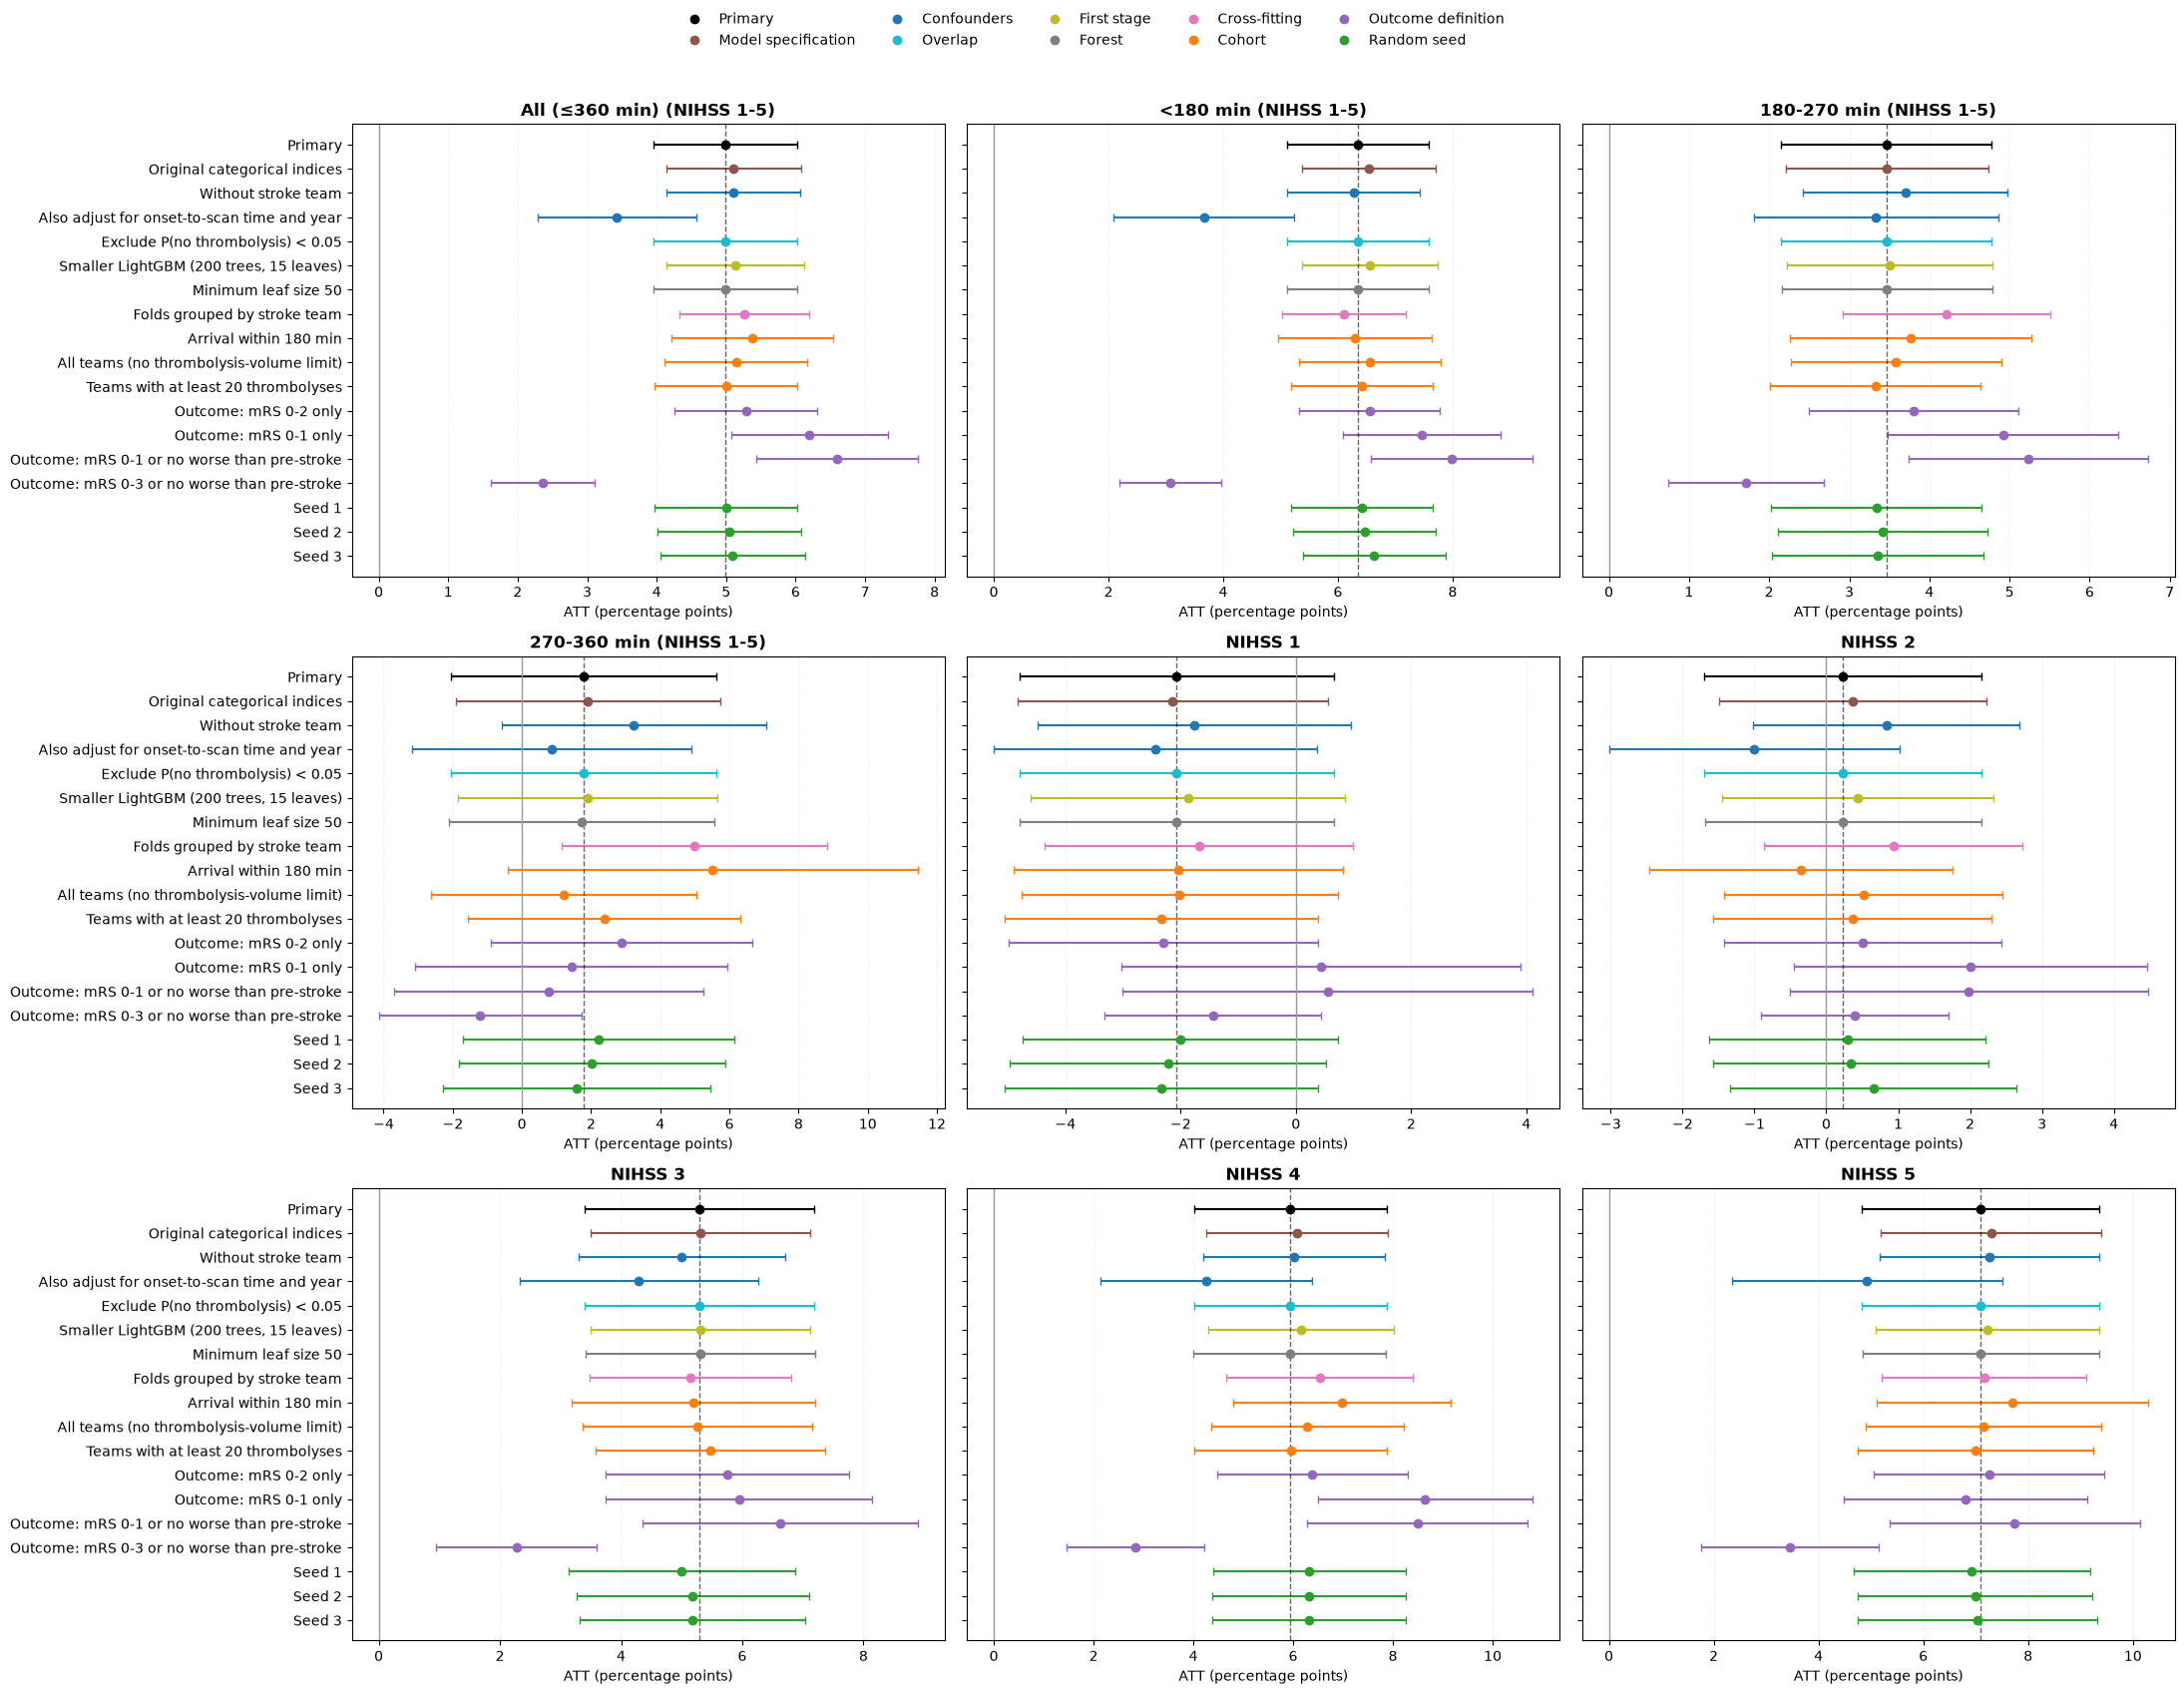

In [23]:
category_colours = {
    "Primary": "black", "Model specification": "#8c564b", "Confounders": "#1f77b4", "Overlap": "#17becf",
    "First stage": "#bcbd22", "Forest": "#7f7f7f", "Cross-fitting": "#e377c2",
    "Cohort": "#ff7f0e", "Outcome definition": "#9467bd", "Random seed": "#2ca02c",
}
fig, axes = plt.subplots(3, 3, figsize=(22, 17), sharey=True)
y_pos = {a: i for i, a in enumerate(analysis_order[::-1])}
for ax, column in zip(axes.flat, column_order):
    df = sens[sens["column"] == column]
    for _, r in df.iterrows():
        colour = category_colours[r["category"]]
        ax.errorbar(100 * r["att"], y_pos[r["analysis"]],
                    xerr=[[100 * (r["att"] - r["att_ci_lower"])], [100 * (r["att_ci_upper"] - r["att"])]],
                    fmt="o", color=colour, ecolor=colour, capsize=3, markersize=6)
    ax.axvline(100 * df.loc[df["analysis"] == "Primary", "att"].iloc[0], color="black", linestyle="--", lw=1, alpha=0.6)
    ax.axvline(0, color="0.6", lw=1)
    ax.set_title(column if column.startswith("NIHSS") else f"{column} (NIHSS 1-5)", fontweight="bold")
    ax.set_xlabel("ATT (percentage points)")
    ax.grid(axis="x", alpha=0.3, linestyle=":")
for ax in axes.flat[len(column_order):]:
    ax.axis("off")
axes[0, 0].set_yticks(list(y_pos.values()))
axes[0, 0].set_yticklabels(list(y_pos.keys()))
for ax in axes[:, 0]:
    ax.tick_params(labelleft=True)
handles = [plt.Line2D([], [], marker="o", color=c, linestyle="", label=k) for k, c in category_colours.items()]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(f"{OUTPUT_DIR}/{prefix}_sensitivity.png", dpi=300)
plt.show()

**Results.** The plot shows the same pattern as the table:
* most analyses cluster around the primary estimate;
* adjusting for onset-to-scan time and year shifts the early-window and NIHSS 3–5 estimates towards zero;
* the excellent-outcome definitions shift them away from zero;
* the 270–360 min window has wide CIs in every analysis;
* NIHSS 1–2 estimates straddle zero, and NIHSS 3–5 estimates are above zero in every analysis.

## 10.3 E-values for unmeasured confounding

The E-value is the minimum strength of association, on the risk-ratio scale, that an unmeasured confounder would need with **both** thrombolysis and good outcome, beyond those adjusted for, to fully explain away the effect (VanderWeele & Ding, *Ann Intern Med* 2017;167:268–274).

The ATT is a risk difference. To turn it into a risk ratio, the treated patients' observed good-outcome proportion (p₁) is compared with their estimated proportion without treatment, p₀ = p₁ − ATT. The same is done for the CI limit closest to no effect; the CI-limit E-value is 1 if the CI includes no effect. This conversion is approximate. E-values are given overall, by window and by NIHSS.

In [24]:
def e_value(rr):
    rr = np.asarray(rr, dtype=float)
    rr = np.where(rr < 1, 1 / rr, rr)
    return rr + np.sqrt(rr * (rr - 1))

ev = effects[(effects["nihss"] == "1-5") | (effects["treatment_group"] == ALL_TREATED)].copy()
ev["risk_ratio"] = ev["p_treated"] / (ev["p_treated"] - ev["att"])
closest = np.where(ev["att"] >= 0, ev["att_ci_lower"], ev["att_ci_upper"])
crosses_null = (ev["att_ci_lower"] <= 0) & (ev["att_ci_upper"] >= 0)
ev["e_value"] = e_value(ev["risk_ratio"])
ev["e_value_ci"] = np.where(crosses_null, 1.0, e_value(ev["p_treated"] / (ev["p_treated"] - closest)))
ev = ev[["treatment_group", "nihss", "n_treated", "att", "att_ci_lower", "att_ci_upper",
         "p_treated", "risk_ratio", "e_value", "e_value_ci"]]
ev.to_csv(f"{OUTPUT_DIR}/{prefix}_e_values.csv", index=False)
ev.round(3)

,treatment_group,nihss,n_treated,att,att_ci_lower,att_ci_upper,p_treated,risk_ratio,e_value,e_value_ci
0,All (≤360 min),1-5,13380,0.050,0.040,0.060,0.774,1.069,1.340,1.292
1,All (≤360 min),1,722,-0.021,-0.048,0.007,0.846,0.976,1.183,1.000
2,All (≤360 min),2,1747,0.002,-0.017,0.022,0.837,1.003,1.055,1.000
3,All (≤360 min),3,2785,0.053,0.034,0.072,0.815,1.070,1.342,1.257
4,All (≤360 min),4,3952,0.059,0.040,0.079,0.764,1.084,1.387,1.297
5,All (≤360 min),5,4174,0.071,0.048,0.093,0.718,1.110,1.458,1.350
6,<180 min,1-5,7390,0.063,0.051,0.076,0.787,1.088,1.396,1.342
12,180-270 min,1-5,5514,0.035,0.021,0.048,0.758,1.048,1.272,1.202
18,270-360 min,1-5,476,0.018,-0.021,0.056,0.771,1.024,1.179,1.000


**Results.**
* **E-values are modest:**
  * 1.34 overall (CI limit 1.29);
  * 1.40 within 180 min (1.34);
  * 1.27 at 180–270 min (1.20);
  * 1.34–1.46 at NIHSS 3–5 (CI limits 1.26–1.35);
  * 1 for the CI limit at NIHSS 1–2 and at 270–360 min, where the CIs include no effect.
* An unmeasured confounder associated with both thrombolysis and good outcome by a risk ratio of about 1.3–1.4, beyond the measured characteristics, could explain away the effect.
* E-values are naturally small here because good outcome is common (77% in treated patients), so a 5-point difference is a risk ratio of only 1.07. Sensemakr (Section 10.4) measures confounding on a scale that is not compressed in this way.
* Plausible unmeasured confounders include:
  * rapidly improving symptoms;
  * how disabling the deficit is (not captured by NIHSS);
  * contraindications such as recent surgery or bleeding risk.

## 10.4 Sensitivity to unmeasured confounding: sensemakr

Cinelli and Hazlett's omitted variable bias framework describes the strength of an unmeasured confounder by its partial R². This is the share of the remaining (residual) variance of treatment and of outcome that the confounder explains. The framework gives:

* **Robustness value RV_q** (q = 1): the minimum partial R² that a confounder would need with *both* thrombolysis and good outcome to reduce the estimate to zero.
* **RV_q,alpha**: the same, to make the 95% confidence interval include zero.
* **Partial R² of treatment with outcome**: an extreme-scenario bound. A confounder that explained all the remaining variation in outcome would still need at least this partial R² with thrombolysis to remove the effect.
* **Benchmark bounds**: the adjusted estimate (with 95% CI) if a confounder were 1, 2 or 3 times as strongly associated with thrombolysis and with outcome as an observed covariate.

Unlike E-values, robustness values are on the partial R² scale, so they are not compressed by the high rate of good outcome in mild stroke.

The framework applies to linear regression, so it cannot be applied to the causal forest itself. Instead, a linear probability model is fitted, adjusting for the same confounders as the forest's first-stage models (W): good outcome ~ thrombolysed + W, with stroke team and ethnicity as indicator variables. It is fitted for:
* all thrombolysed patients vs all untreated patients;
* patients thrombolysed in each window vs all untreated patients;
* all thrombolysed vs untreated patients within each NIHSS score.

Patients with a missing confounder are excluded from these models.

The linear model is a simpler stand-in for the causal forest: it has no non-linear effects or interactions, and its predictions are not constrained to lie between 0 and 1. Benchmarks are pre-stroke mRS, NIHSS and age. Within a single NIHSS score, NIHSS is constant and is not used.

The first cell implements the formulas of the sensemakr package directly, because the Python package (PySensemakr 0.0.8) is not compatible with pandas 3. The implementation reproduces the package's published Darfur example (estimate, robustness values and benchmark bounds). The second cell fits the models and tabulates the results, and the third draws the sensitivity contours.

Cinelli C, Hazlett C. Making sense of sensitivity: extending omitted variable bias. *J R Stat Soc Series B* 2020;82:39–67.

In [25]:
from scipy import stats as _stats
import statsmodels.api as _sm


def sensemakr_analysis(model, treatment, benchmarks, kd=(1, 2, 3), q=1.0, alpha=0.05):
    """Cinelli & Hazlett (2020) omitted-variable-bias sensitivity analysis for one OLS coefficient.

    Implements the formulas of the sensemakr package directly (the PySensemakr package is not
    compatible with pandas 3). Returns a one-row DataFrame of sensitivity statistics and a
    DataFrame of bounds: the adjusted estimate if an unobserved confounder were kd times as
    strongly associated with treatment and with outcome as each benchmark covariate.
    """
    est, se, t = model.params[treatment], model.bse[treatment], model.tvalues[treatment]
    dof = model.df_resid
    t_crit = _stats.t.ppf(1 - alpha / 2, dof - 1)

    # Partial R2 of treatment with outcome, and robustness values
    r2yd_x = t**2 / (t**2 + dof)
    f_q = q * abs(t) / np.sqrt(dof)
    rv_q = 0.5 * (np.sqrt(f_q**4 + 4 * f_q**2) - f_q**2)
    f_crit = t_crit / np.sqrt(dof - 1)
    f_qa = f_q - f_crit
    if f_qa < 0:
        rv_qa = 0.0
    elif f_q > 1 / f_crit:  # extreme case (very large t), as in the sensemakr package
        rv_qa = (f_q**2 - f_crit**2) / (1 + f_q**2)
    else:
        rv_qa = 0.5 * (np.sqrt(f_qa**4 + 4 * f_qa**2) - f_qa**2)
    sens_stats = pd.DataFrame([{
        "estimate": est, "se": se, "t": t, "dof": dof, "t_crit": t_crit,
        "r2yd_x": r2yd_x, "rv_q": rv_q, "rv_qa": rv_qa,
    }])

    # Benchmark bounds: partial R2 of each benchmark with treatment (given other covariates)
    # and with outcome (given treatment and other covariates)
    exog = pd.DataFrame(model.model.exog, columns=model.model.exog_names)
    treatment_model = _sm.OLS(exog[treatment], exog.drop(columns=treatment)).fit()
    rows = []
    for b in benchmarks:
        t_dx = treatment_model.tvalues[b]
        r2dxj_x = t_dx**2 / (t_dx**2 + treatment_model.df_resid)
        r2yxj_dx = model.tvalues[b]**2 / (model.tvalues[b]**2 + dof)
        for k in kd:
            row = {"benchmark": b, "kd": k}
            if k * r2dxj_x >= 1:
                rows.append(row)
                continue
            r2dz_x = k * r2dxj_x / (1 - r2dxj_x)
            r2zxj_xd = k * r2dxj_x**2 / ((1 - k * r2dxj_x) * (1 - r2dxj_x))
            r2yz_dx = min(1.0, ((np.sqrt(k) + np.sqrt(r2zxj_xd)) / np.sqrt(1 - r2zxj_xd))**2
                          * r2yxj_dx / (1 - r2yxj_dx))
            bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
            adj_est = np.sign(est) * (abs(est) - bias)
            adj_se = se * np.sqrt((1 - r2yz_dx) / (1 - r2dz_x) * dof / (dof - 1))
            row.update({"r2dz_x": r2dz_x, "r2yz_dx": r2yz_dx, "adjusted_estimate": adj_est,
                        "adjusted_ci_lower": adj_est - t_crit * adj_se,
                        "adjusted_ci_upper": adj_est + t_crit * adj_se})
            rows.append(row)
    return sens_stats, pd.DataFrame(rows)


def adjusted_estimate_grid(est, se, dof, r2dz_x, r2yz_dx):
    """Adjusted estimate (bias towards zero) over a grid of confounder partial R2 values."""
    bias = se * np.sqrt(r2yz_dx * r2dz_x / (1 - r2dz_x) * dof)
    return np.sign(est) * (abs(est) - bias)


BENCHMARK_MARKERS = {"prior_disability": "o", "stroke_severity": "s", "age": "^"}
BENCHMARK_NAMES = {"prior_disability": "pre-stroke mRS", "stroke_severity": "NIHSS", "age": "age"}


def plot_sensemakr_contours(sens_stats, sens_bounds, labels, filename, scale=100, unit="percentage points"):
    """One contour plot per treatment strategy: adjusted estimate against the partial R2 of a
    hypothetical confounder with treatment (x) and with outcome (y). The red dashed line is
    where the estimate would fall to zero; markers show confounders 1x, 2x and 3x as strong
    as each benchmark covariate."""
    strategies = list(sens_stats.index)
    ncols = 4
    nrows = int(np.ceil(len(strategies) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.9 * nrows), squeeze=False)
    for ax, strategy in zip(axes.flat, strategies):
        st = sens_stats.loc[strategy]
        b = sens_bounds[(sens_bounds["treatment_group"] == strategy)].dropna(subset=["r2dz_x"])
        lim = max(0.05, 1.2 * max(b["r2dz_x"].max(), b["r2yz_dx"].max(), st["rv_q"]))
        lim = min(lim, 0.95)
        grid = np.linspace(0, lim, 201)
        gx, gy = np.meshgrid(grid, grid)
        z = scale * adjusted_estimate_grid(st["estimate"], st["se"], st["dof"], gx, gy)
        cs = ax.contour(gx, gy, z, levels=8, colors="grey", linewidths=0.7)
        ax.clabel(cs, fontsize=7, fmt="%.0f")
        ax.contour(gx, gy, z, levels=[0], colors="red", linestyles="--", linewidths=1.3)
        for _, r in b.iterrows():
            ax.plot(r["r2dz_x"], r["r2yz_dx"], BENCHMARK_MARKERS.get(r["benchmark"], "x"),
                    color="black", ms=4 + r["kd"])
        ax.plot(0, 0, "*", color="tab:blue", ms=9)
        ax.set_xlim(0, lim)
        ax.set_ylim(0, lim)
        ax.set_title(labels.get(strategy, strategy).replace("\n", " "), fontsize=10)
        ax.set_xlabel("Partial R² of confounder with treatment", fontsize=8)
        ax.set_ylabel("Partial R² of confounder with outcome", fontsize=8)
        ax.tick_params(labelsize=7)
    for ax in axes.flat[len(strategies):]:
        ax.axis("off")
    handles = [plt.Line2D([], [], color="red", linestyle="--", label="Adjusted estimate = 0"),
               plt.Line2D([], [], marker="*", color="tab:blue", linestyle="", label="Unadjusted estimate")]
    used = sorted(set(sens_bounds["benchmark"]), key=list(BENCHMARK_MARKERS).index)
    handles += [plt.Line2D([], [], marker=BENCHMARK_MARKERS.get(b, "x"), color="black", linestyle="",
                           label=f"1x, 2x, 3x {BENCHMARK_NAMES.get(b, b)}") for b in used]
    fig.legend(handles=handles, loc="lower right", fontsize=8, frameon=False)
    fig.suptitle(f"Sensitivity contours: adjusted effect ({unit})", fontsize=12)
    fig.tight_layout()
    fig.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()


def format_sensemakr_tables(sens_stats, sens_bounds, labels, scale=100, decimals=1):
    """Publication tables: robustness statistics, and adjusted estimates for each benchmark."""
    fmt = lambda x: f"{scale * x:.{decimals}f}"
    summary = pd.DataFrame({
        "n": sens_stats["n"].astype(int).to_numpy(),
        "estimate (95% CI)": [f"{fmt(r.estimate)} ({fmt(r.estimate - r.t_crit * r.se)}, {fmt(r.estimate + r.t_crit * r.se)})"
                              for r in sens_stats.itertuples()],
        "partial R2 of treatment (%)": (100 * sens_stats["r2yd_x"]).round(2).to_numpy(),
        "RV_q (%)": (100 * sens_stats["rv_q"]).round(1).to_numpy(),
        "RV_q,alpha (%)": (100 * sens_stats["rv_qa"]).round(1).to_numpy(),
    }, index=[labels.get(s, s).replace("\n", " ") for s in sens_stats.index])
    b = sens_bounds.copy()
    b["adjusted (95% CI)"] = [
        "" if pd.isna(r.adjusted_estimate) else
        f"{fmt(r.adjusted_estimate)} ({fmt(r.adjusted_ci_lower)}, {fmt(r.adjusted_ci_upper)})"
        for r in b.itertuples()]
    b["bound"] = b["kd"].astype(str) + "x " + b["benchmark"].map(lambda x: BENCHMARK_NAMES.get(x, x))
    bounds_table = b.pivot(index="treatment_group", columns="bound", values="adjusted (95% CI)")
    bounds_table = bounds_table.reindex(index=list(sens_stats.index),
                                        columns=list(dict.fromkeys(b["bound"])))
    bounds_table.index = [labels.get(s, s).replace("\n", " ") for s in bounds_table.index]
    return summary, bounds_table

In [26]:
# Linear probability model of thrombolysed vs untreated patients, adjusting for the causal forest's
# first-stage confounders (W): good outcome ~ thrombolysed + W, with stroke team and ethnicity as indicator
# variables. Fitted for all windows combined, for each window (vs all untreated patients), and for all
# windows combined within each NIHSS score (where NIHSS is constant and is dropped from the model and benchmarks).
SENS_BENCHMARKS = ["prior_disability", "stroke_severity", "age"]
SENS_GROUPS = [ALL_TREATED] + GROUP_ORDER + [f"NIHSS {n}" for n in NIHSS_VALUES]
SENS_LABELS = {g: g for g in SENS_GROUPS}
SENS_LABELS.update({f"NIHSS {n}": f"{ALL_TREATED}, NIHSS {n}" for n in NIHSS_VALUES})

sens_covariates = pd.get_dummies(data[W_FEATURES].astype({c: str for c in CATEGORICAL_FEATURES}),
                                 columns=CATEGORICAL_FEATURES, drop_first=True, dtype=float)
sens_outcome = good_outcome(data).astype(float).to_numpy()
is_untreated = (data["treatment_group"] == CONTROL_GROUP).to_numpy()

sens_rows, sens_bound_rows = [], []
for group in SENS_GROUPS:
    if group in GROUP_ORDER:  # one window vs all untreated patients
        is_treated = (data["treatment_group"] == group).to_numpy()
        in_model = is_treated | is_untreated
    else:  # all windows combined, in the whole cohort or within one NIHSS score
        is_treated = ~is_untreated
        in_model = (np.ones(len(data), dtype=bool) if group == ALL_TREATED
                    else (data["stroke_severity"] == int(group.split()[-1])).to_numpy())
    df = sens_covariates[in_model].assign(treated=is_treated[in_model].astype(float),
                                          y=sens_outcome[in_model]).dropna()
    X_lpm = df.drop(columns="y")
    X_lpm = X_lpm.loc[:, X_lpm.std() > 0]  # drop columns that are constant in this subset
    lpm = _sm.OLS(df["y"], _sm.add_constant(X_lpm, has_constant="add")).fit()
    stats_row, bounds = sensemakr_analysis(lpm, "treated", [b for b in SENS_BENCHMARKS if b in X_lpm.columns])
    sens_rows.append(stats_row.assign(treatment_group=group, n=len(df)))
    sens_bound_rows.append(bounds.assign(treatment_group=group))

sensemakr_stats = pd.concat(sens_rows).set_index("treatment_group")
sensemakr_bounds = pd.concat(sens_bound_rows, ignore_index=True)
sensemakr_stats.to_csv(f"{OUTPUT_DIR}/{prefix}_sensemakr.csv")
sensemakr_bounds.to_csv(f"{OUTPUT_DIR}/{prefix}_sensemakr_bounds.csv", index=False)

sensemakr_summary, sensemakr_bounds_table = format_sensemakr_tables(sensemakr_stats, sensemakr_bounds, SENS_LABELS)
display(sensemakr_summary)
display(sensemakr_bounds_table)

,n,estimate (95% CI),partial R2 of treatment (%),RV_q (%),"RV_q,alpha (%)"
All (≤360 min),58389,"5.2 (4.3, 6.1)",0.22,4.6,3.8
<180 min,52399,"7.0 (5.8, 8.1)",0.29,5.2,4.4
180-270 min,50523,"3.6 (2.4, 4.9)",0.07,2.5,1.7
270-360 min,45485,"2.6 (-1.2, 6.4)",0.00,0.6,0.0
"All (≤360 min), NIHSS 1",11002,"-1.0 (-3.8, 1.8)",0.00,0.7,0.0
"All (≤360 min), NIHSS 2",14145,"1.0 (-1.0, 3.1)",0.01,0.8,0.0
"All (≤360 min), NIHSS 3",12856,"6.4 (4.5, 8.3)",0.35,5.7,4.1
"All (≤360 min), NIHSS 4",10968,"7.3 (5.4, 9.2)",0.53,7.0,5.3
"All (≤360 min), NIHSS 5",9418,"8.0 (6.0, 10.1)",0.62,7.6,5.7


bound,1x pre-stroke mRS,2x pre-stroke mRS,3x pre-stroke mRS,1x NIHSS,2x NIHSS,3x NIHSS,1x age,2x age,3x age
All (≤360 min),"4.7 (3.8, 5.6)","4.1 (3.2, 5.0)","3.6 (2.7, 4.5)","-1.7 (-2.7, -0.8)","-10.3 (-11.3, -9.3)","-21.5 (-22.6, -20.4)","4.6 (3.7, 5.4)","3.9 (3.1, 4.8)","3.3 (2.4, 4.2)"
<180 min,"6.4 (5.3, 7.5)","5.9 (4.7, 7.0)","5.3 (4.2, 6.5)","0.1 (-1.0, 1.3)","-7.8 (-9.0, -6.5)","-17.1 (-18.4, -15.8)","6.5 (5.4, 7.5)","5.9 (4.9, 7.0)","5.4 (4.4, 6.5)"
180-270 min,"3.2 (2.0, 4.5)","2.9 (1.6, 4.1)","2.5 (1.2, 3.7)","-2.5 (-3.8, -1.2)","-9.2 (-10.5, -7.9)","-16.6 (-18.0, -15.3)","2.9 (1.7, 4.1)","2.2 (0.9, 3.4)","1.4 (0.2, 2.6)"
270-360 min,"2.2 (-1.6, 6.0)","1.8 (-2.0, 5.7)","1.5 (-2.3, 5.3)","-1.9 (-5.7, 1.9)","-6.4 (-10.1, -2.6)","-10.9 (-14.6, -7.2)","1.4 (-2.3, 5.2)","0.3 (-3.4, 4.0)","-0.8 (-4.5, 2.8)"
"All (≤360 min), NIHSS 1","-0.4 (-3.2, 2.4)","0.2 (-2.6, 3.0)","0.8 (-2.0, 3.5)",NaN,NaN,NaN,"-0.4 (-3.2, 2.3)","0.1 (-2.6, 2.9)","0.7 (-2.0, 3.4)"
"All (≤360 min), NIHSS 2","0.3 (-1.7, 2.4)","-0.4 (-2.5, 1.7)","-1.1 (-3.2, 1.0)",NaN,NaN,NaN,"0.1 (-1.9, 2.2)","-0.8 (-2.8, 1.2)","-1.7 (-3.7, 0.3)"
"All (≤360 min), NIHSS 3","6.0 (4.1, 7.9)","5.6 (3.7, 7.5)","5.2 (3.2, 7.1)",NaN,NaN,NaN,"5.8 (3.9, 7.7)","5.2 (3.3, 7.0)","4.6 (2.7, 6.4)"
"All (≤360 min), NIHSS 4","7.3 (5.3, 9.2)","7.2 (5.3, 9.2)","7.2 (5.2, 9.2)",NaN,NaN,NaN,"6.6 (4.8, 8.5)","5.9 (4.1, 7.7)","5.2 (3.4, 7.0)"
"All (≤360 min), NIHSS 5","7.3 (5.2, 9.4)","6.5 (4.3, 8.6)","5.6 (3.4, 7.9)",NaN,NaN,NaN,"7.2 (5.2, 9.3)","6.5 (4.5, 8.4)","5.7 (3.7, 7.6)"


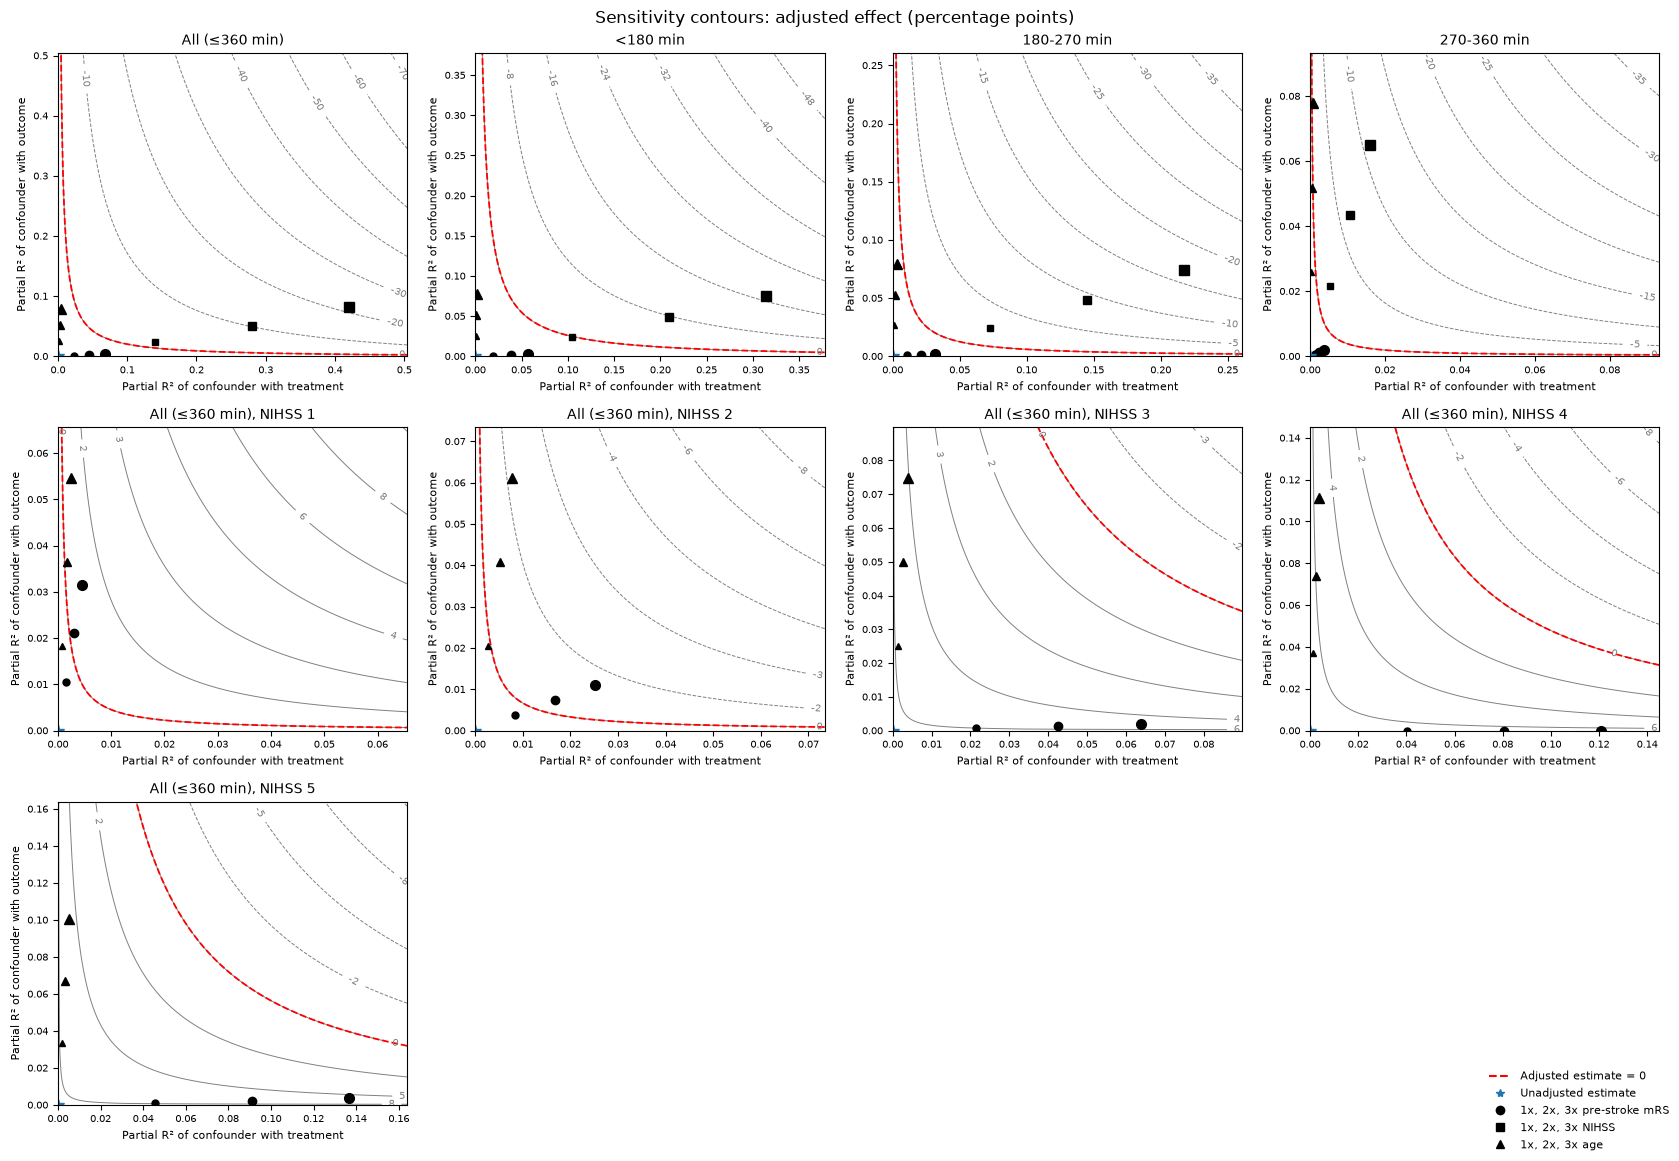

In [27]:
plot_sensemakr_contours(sensemakr_stats, sensemakr_bounds, SENS_LABELS,
                        f"{OUTPUT_DIR}/{prefix}_sensemakr_contours.png")

**Results.** The linear probability model gives effects close to the causal forest ATT.

| Group | n | Estimate, points (95% CI) | RV_q | RV_q,α | 3× pre-stroke mRS | 3× age | 1× NIHSS |
|---|---|---|---|---|---|---|---|
| All (≤ 360 min) | 58,389 | 5.2 (4.3 to 6.1) | 4.6% | 3.8% | 3.6 (2.7 to 4.5) | 3.3 (2.4 to 4.2) | −1.7 (−2.7 to −0.8) |
| < 180 min | 52,399 | 7.0 (5.8 to 8.1) | 5.2% | 4.4% | 5.3 (4.2 to 6.5) | 5.4 (4.4 to 6.5) | 0.1 (−1.0 to 1.3) |
| 180–270 min | 50,523 | 3.6 (2.4 to 4.9) | 2.5% | 1.7% | 2.5 (1.2 to 3.7) | 1.4 (0.2 to 2.6) | −2.5 (−3.8 to −1.2) |
| 270–360 min | 45,485 | 2.6 (−1.2 to 6.4) | 0.6% | 0.0% | 1.5 (−2.3 to 5.3) | −0.8 (−4.5 to 2.8) | −1.9 (−5.7 to 1.9) |
| NIHSS 1 | 11,002 | −1.0 (−3.8 to 1.8) | 0.7% | 0.0% | 0.8 (−2.0 to 3.5) | 0.7 (−2.0 to 3.4) | – |
| NIHSS 2 | 14,145 | 1.0 (−1.0 to 3.1) | 0.8% | 0.0% | −1.1 (−3.2 to 1.0) | −1.7 (−3.7 to 0.3) | – |
| NIHSS 3 | 12,856 | 6.4 (4.5 to 8.3) | 5.7% | 4.1% | 5.2 (3.2 to 7.1) | 4.6 (2.7 to 6.4) | – |
| NIHSS 4 | 10,968 | 7.3 (5.4 to 9.2) | 7.0% | 5.3% | 7.2 (5.2 to 9.2) | 5.2 (3.4 to 7.0) | – |
| NIHSS 5 | 9,418 | 8.0 (6.0 to 10.1) | 7.6% | 5.7% | 5.6 (3.4 to 7.9) | 5.7 (3.7 to 7.6) | – |

*(Benchmark columns: adjusted estimate, points (95% CI), for a confounder 3 times as strong as pre-stroke mRS or age, or as strong as NIHSS.)*

* **Overall.** To remove the estimate, an unmeasured confounder would need to explain 4.6% of the residual variance of both thrombolysis and outcome. To make it non-significant, it would need 3.8%.
* **Age and pre-stroke mRS benchmarks.** A confounder up to 3 times as strong as either would leave a clear benefit overall and within 180 min.
* **NIHSS benchmark.** A confounder as strong as NIHSS would remove or reverse the pooled estimates. NIHSS is by far the strongest determinant of treatment, so a confounder of comparable strength is a real concern for the pooled estimate.
* **Within NIHSS strata** this dominant source of selection is removed.
  * NIHSS 3–5: robustness values are 5.7–7.6%. Benchmark confounders up to 3 times as strong as age or pre-stroke mRS leave benefits of 4.6–7.2 points, all with CIs above zero.
  * NIHSS 1–2: estimates are close to zero with CIs that include zero, and robustness values are below 1%.
* **Contour plots.** These show the adjusted estimate for any combination of confounder strengths, with the benchmarks marked. The red dashed line is where the estimate falls to zero.

## 10.5 Leave-one-out analysis of the main confounders

Each of the three strongest measured confounders (NIHSS, age and pre-stroke mRS) is removed in turn from both the effect modifiers (X) and the first-stage confounders (W). The causal forest and the doubly robust ATT are then re-estimated.

Leaving out a measured confounder is a deliberate misspecification. The change in the ATT shows how much each result depends on adjusting for that confounder. It also suggests how much bias an unmeasured confounder of similar strength, acting in the same direction, could cause.

Results are given for each window and all windows combined, and for all windows combined within each NIHSS score. NIHSS subgroups use each patient's recorded NIHSS, including when NIHSS is left out of the model. Each refit takes about as long as the primary model.

In [28]:
# Leave-one-out sensitivity analysis: remove each main confounder from X and W in turn
LOO_FEATURES = {
    "Without NIHSS": "stroke_severity",
    "Without age": "age",
    "Without pre-stroke mRS": "prior_disability",
}
primary_effects = effects if "effects" in globals() else pd.read_csv(f"{OUTPUT_DIR}/{prefix}_effects.csv",
                                                                     dtype={"nihss": str})
loo_results = [primary_effects.assign(analysis="Primary", category="Primary")]
for label, feature in LOO_FEATURES.items():
    est_loo, X_loo, _, y_loo, arm_loo, seconds = fit_causal_forest(
        data,
        x_features=[f for f in X_FEATURES if f != feature],
        w_features=[f for f in W_FEATURES if f != feature],
    )
    loo_results.append(dr_effects(est_loo, X_loo, y_loo, arm_loo, data["stroke_severity"], label, "Leave one out"))
    print(f"{label}: {seconds / 60:.1f} min")

# Each window and all combined (NIHSS 1-5), then all windows combined within each NIHSS score
loo_df = pd.concat(loo_results, ignore_index=True)
loo_df = loo_df[(loo_df["nihss"] == "1-5") | (loo_df["treatment_group"] == ALL_TREATED)].copy()
loo_df["column"] = np.where(loo_df["nihss"] == "1-5", loo_df["treatment_group"], "NIHSS " + loo_df["nihss"])
primary_att = loo_df[loo_df["analysis"] == "Primary"].set_index("column")["att"]
loo_df["change_pp"] = 100 * (loo_df["att"] - loo_df["column"].map(primary_att))
loo_df["att_pp"] = [fmt_pp(*r) for r in loo_df[["att", "att_ci_lower", "att_ci_upper"]].to_numpy()]
loo_df.to_csv(f"{OUTPUT_DIR}/{prefix}_leave_one_out.csv", index=False)

loo_rows = [ALL_TREATED] + GROUP_ORDER + [f"NIHSS {n}" for n in NIHSS_VALUES]
loo_columns = ["Primary", *LOO_FEATURES]
for values, title in [("att_pp", "Doubly robust ATT, percentage points (95% CI)"),
                      ("change_pp", "Change from the primary estimate, percentage points")]:
    print(title)
    display(loo_df.pivot(index="column", columns="analysis", values=values)
            .reindex(index=loo_rows, columns=loo_columns).round(1))

Without NIHSS: 1.6 min
Without age: 1.5 min
Without pre-stroke mRS: 1.6 min
Doubly robust ATT, percentage points (95% CI)


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
column,,,,
All (≤360 min),"5.0 (4.0, 6.0)","-0.9 (-1.7, -0.1)","5.7 (4.6, 6.7)","5.5 (4.5, 6.5)"
<180 min,"6.3 (5.1, 7.6)","0.1 (-0.9, 1.2)","6.9 (5.6, 8.1)","7.2 (6.0, 8.4)"
180-270 min,"3.5 (2.1, 4.8)","-2.1 (-3.3, -0.9)","4.3 (3.0, 5.7)","3.5 (2.2, 4.9)"
270-360 min,"1.8 (-2.1, 5.6)","-2.8 (-6.7, 1.0)","2.9 (-1.0, 6.8)","2.2 (-1.6, 6.1)"
NIHSS 1,"-2.1 (-4.8, 0.7)","-27.7 (-33.0, -22.5)","-1.7 (-4.5, 1.1)","-1.5 (-4.3, 1.2)"
NIHSS 2,"0.2 (-1.7, 2.2)","-4.5 (-7.1, -2.0)","1.1 (-0.8, 3.1)","1.0 (-1.0, 2.9)"
NIHSS 3,"5.3 (3.4, 7.2)","5.2 (3.4, 7.0)","6.1 (4.3, 8.0)","6.0 (4.1, 7.9)"
NIHSS 4,"5.9 (4.0, 7.9)","1.9 (0.5, 3.4)","6.4 (4.4, 8.4)","6.9 (5.0, 8.8)"
NIHSS 5,"7.1 (4.8, 9.3)","-1.5 (-2.9, -0.1)","7.8 (5.5, 10.1)","7.0 (4.8, 9.2)"


Change from the primary estimate, percentage points


analysis,Primary,Without NIHSS,Without age,Without pre-stroke mRS
column,,,,
All (≤360 min),0.0,-5.9,0.7,0.5
<180 min,0.0,-6.2,0.5,0.9
180-270 min,0.0,-5.6,0.9,0.1
270-360 min,0.0,-4.6,1.1,0.5
NIHSS 1,0.0,-25.6,0.4,0.5
NIHSS 2,0.0,-4.7,0.9,0.8
NIHSS 3,0.0,-0.1,0.8,0.7
NIHSS 4,0.0,-4.0,0.5,1.0
NIHSS 5,0.0,-8.6,0.8,-0.1


**Results.**

| | Primary | Without NIHSS | Without age | Without pre-stroke mRS |
|---|---|---|---|---|
| All (≤ 360 min) | 5.0 | −0.9 (−1.7 to −0.1) | 5.7 | 5.5 |
| < 180 min | 6.3 | 0.1 | 6.9 | 7.2 |
| 180–270 min | 3.5 | −2.1 | 4.3 | 3.5 |
| 270–360 min | 1.8 | −2.8 | 2.9 | 2.2 |
| NIHSS 1 | −2.1 | −27.7 | −1.7 | −1.5 |
| NIHSS 2 | 0.2 | −4.5 | 1.1 | 1.0 |
| NIHSS 3 | 5.3 | 5.2 | 6.1 | 6.0 |
| NIHSS 4 | 5.9 | 1.9 | 6.4 | 6.9 |
| NIHSS 5 | 7.1 | −1.5 | 7.8 | 7.0 |

*(Doubly robust ATT, percentage points.)*

* **Without NIHSS the benefit disappears** (overall −0.9, a change of −5.9 points). Thrombolysed patients have more severe strokes, which carry a worse prognosis, so failing to adjust for severity biases the estimate strongly *against* thrombolysis. The estimates within NIHSS scores become severely distorted (for example −27.7 at NIHSS 1), because the model can no longer separate patients by severity.
* **Without age** the estimates increase by 0.4 to 1.1 points.
* **Without pre-stroke mRS** they change by −0.1 to +1.0 points.
* Thrombolysed patients are younger and less disabled, so omitting age or pre-stroke mRS biases the estimate in favour of thrombolysis, but only modestly.

So the results depend critically on adjustment for stroke severity. An unmeasured confounder that acts like NIHSS, such as how disabling the deficit is, would most likely lead to *underestimating* the benefit. An unmeasured confounder as strong as age or pre-stroke mRS, acting in their direction, would inflate the benefit by about 1 point or less.

# 11. Summary of observations and conclusions

## Observations

1. **Cohort and selection.**
   * 58,389 patients with mild ischaemic stroke (NIHSS 1–5) arrived within 4 hours; 23% were thrombolysed (7,390 within 180 min, 5,514 at 180–270 min, 476 at 270–360 min).
   * Thrombolysed patients had more severe strokes, less pre-stroke disability, were younger and were rarely anticoagulated.
   * Unadjusted, 77.4% of thrombolysed and 73.8% of untreated patients had a good outcome. In-hospital death was about 2% in all groups.
2. **Model quality.**
   * The first-stage outcome model discriminated moderately (AUC 0.72). It was well calibrated in the large, with somewhat over-extreme predictions (slope 0.88).
   * Treatment was well predicted (AUC 0.81 for any thrombolysis).
   * Overlap for the effect in the treated was good: no treated patient had a probability of no thrombolysis below 0.05.
3. **Overall effect.** In thrombolysed patients, thrombolysis was associated with a **5.0 percentage-point** higher probability of a good outcome (95% CI 4.0 to 6.0), a risk ratio of 1.07 (1.05 to 1.08). The forest's mean CATE agreed (5.0). The effect if everyone were treated (ATE) was smaller (4.1 within 180 min), consistent with clinicians selecting patients who benefit more.
4. **Timing.** The benefit fell with later treatment:
   * within 180 min: 6.3 points (5.1 to 7.6);
   * 180–270 min: 3.5 (2.1 to 4.8);
   * 270–360 min: 1.8 (−2.1 to 5.6), uncertain (476 patients).
5. **Severity.** The benefit depended strongly on NIHSS (p < 0.001):
   * NIHSS 1: −2.1 (−4.8 to 0.7);
   * NIHSS 2: 0.2 (−1.7 to 2.2);
   * NIHSS 3–5: 5.3 to 7.1 points, and up to 9.2 within 180 min at NIHSS 5.

   No other characteristic showed clear variation in benefit. The forest's individual-level estimates were only weakly calibrated (BLP slopes 0.07–0.26), so variation in benefit is best described by these subgroup estimates.
6. **Agreement with the matched target trial emulation.** All estimates were within 2 points (overall 5.0 vs 5.7), with the same pattern by NIHSS and window.
7. **Robustness to analytic choices.**
   * Across model settings, encodings, cross-fitting, cohort definitions and random seeds, the overall estimate was 5.0 to 5.4.
   * Adjusting for onset-to-scan time and year reduced it to 3.4 (2.3 to 4.6).
   * Outcome definitions gave 2.4 (mRS 0–3) to 6.6 (mRS 0–1 or no worse).
   * Benefit at NIHSS 3–5 had a CI above zero in every analysis. Benefit at NIHSS 1 was never detectable.
8. **Unmeasured confounding.**
   * The overall E-value is 1.34 (CI limit 1.29), and the sensemakr robustness value 4.6%.
   * The overall estimate withstands a confounder up to 3 times as strong as age or pre-stroke mRS, but not one as strong as NIHSS.
   * Within NIHSS 3–5, robustness values are 5.7–7.6%.
   * Leaving NIHSS out of the model removed the benefit. Leaving out age or pre-stroke mRS changed it by about 1 point or less.

## Conclusions

* In patients with mild stroke arriving within 4 hours, thrombolysis was associated with a modest benefit in those treated: about 5 percentage points overall and about 6 points if given within 180 minutes. The benefit fell with later treatment and was uncertain beyond 270 minutes.
* The benefit was concentrated in patients with NIHSS 3–5. There was no detectable benefit at NIHSS 1–2, which is consistent with randomised evidence in minor non-disabling stroke (for example PRISMS and ARAMIS).
* The results agree with a matched target trial emulation and are stable across a wide range of analytic choices. Their main dependence is on adjustment for stroke severity. An unmeasured confounder acting like severity, such as how disabling the deficit is, would most likely bias the estimates *against* thrombolysis.

## Limitations

* **Unmeasured confounding.** The main threat is confounding by factors not recorded in SSNAP, especially rapidly improving or non-disabling symptoms and contraindications. The E-values (about 1.3–1.4) show that only modest confounding of this kind would be needed to explain the overall result.
* **Onset-to-scan time.** Adjusting for onset-to-scan time and year reduced the overall estimate to 3.4 points. It is unclear whether this variable should be adjusted for.
* **Timing.** Treatment windows are defined by time of treatment, which is only known for treated patients. Untreated patients have no "time zero", so the comparison is with no treatment at any time, not with delayed treatment.
* **Small groups.** The 270–360 min group and the smaller ethnic groups are small, so their estimates are uncertain. Subgroup p values are not adjusted for multiple testing.
* **Individual-level estimates.** The forest's individual CATEs are not well calibrated, so they should not be used to predict benefit for individual patients.
* **Outcome.** The outcome is mRS at discharge, not at 90 days. Discharge mRS can differ from longer-term outcome, especially in mild stroke.
* **Overlap for the ATE.** Overlap is limited for the ATE, which is therefore reported only where at least 80% of patients have a predicted probability of 0.01 or more for the treatment window.
* **Sensemakr.** It uses a linear probability model as a stand-in for the causal forest.